In [4]:
# -*- coding: utf-8 -*-
"""
循环构建基线模型及不同缓冲距离下的随机森林模型，
并计算 OOB R² 与 OOB RMSE。

因变量
------
lst0603, lst0806, lst0828, lst0803, lst0619, lst0719

模型设置
--------
1. 基线模型（buffer distance = 0 m）：
   仅使用内部变量与控制变量，不加入任何缓冲区变量。

2. 缓冲区模型（buffer distance = 30–300 m，步长30 m）：
   使用内部变量、控制变量，以及相应距离的缓冲区变量。

固定变量（内部变量与控制变量）
----------------------------
TCC, GCI, BCI, WCI, RCI, Shape_Area,
jungong, BAH, BHSD, DIST

缓冲区变量
----------
TCC_bXm, GCI_bXm, BCI_bXm, WCI_bXm,
RCI_bXm, BAH_bXm, BHSD_bXm

说明
----
1. 因变量中的0按缺失值处理并删除；
2. 自变量缺失值用当前模型样本内的中位数填补；
3. 采用随机森林袋外预测（OOB prediction）计算R²和RMSE；
4. 基线模型以及每个缓冲距离模型均重新独立构建；
5. 输出全部模型结果、最佳模型结果、最佳缓冲区模型结果；
6. 输出一个六场景综合双y轴图，以及六张单场景双y轴图；
7. 图中buffer distance = 0表示不包含缓冲区变量的基线模型。

首次运行若缺少依赖，可在Jupyter Notebook中执行：

!pip install pandas numpy scikit-learn matplotlib openpyxl xlrd
"""

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, r2_score


warnings.filterwarnings(
    "ignore",
    category=UserWarning,
)


# =============================================================================
# 0. 参数设置
# =============================================================================

DATA_PATH = Path(
    r"E:\excel\FILES\博士申请\第二篇论文\data"
    r"\wuhuanshiliang\SH_attributes_10000.xls"
)

OUTPUT_DIR = Path(
    r"E:\excel\FILES\博士申请\第二篇论文"
    r"\脚本\Python"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# 因变量
TARGETS = [
    "lst0603",
    "lst0806",
    "lst0828",
    "lst0803",
    "lst0619",
    "lst0719",
]


# 实际缓冲距离：30–300 m，每30 m一档
BUFFER_DISTANCES = list(
    range(30, 301, 30)
)


# 全部模型距离：
# 0 m表示不加入任何缓冲区变量的基线模型
MODEL_DISTANCES = [
    0,
    *BUFFER_DISTANCES,
]


# 固定变量：
# 内部变量 + 控制变量
FIXED_VARS = [
    "TCC",
    "GCI",
    "BCI",
    "WCI",
    "RCI",
    "Shape_Area",
    "jungong",
    "BAH",
    "BHSD",
    "DIST",
]


# 缓冲区变量的基础名称
BUFFER_BASE_VARS = [
    "TCC",
    "GCI",
    "BCI",
    "WCI",
    "RCI",
    "BAH",
    "BHSD",
]


# =============================================================================
# 随机森林参数
# =============================================================================

N_TREES = 1000

MIN_NODE_SIZE = 5

RANDOM_STATE = 42

N_JOBS = -1


# sklearn回归随机森林默认max_features=1.0，
# 即每次分裂考虑全部变量。
#
# 若希望采用更强的随机特征抽样，可改为：
# MAX_FEATURES = "sqrt"
#
# 或：
# MAX_FEATURES = 1 / 3

MAX_FEATURES = 1.0


# =============================================================================
# 场景分组和绘图参数
# =============================================================================

ORANGE_TARGETS = [
    "lst0603",
    "lst0806",
    "lst0828",
]

RED_TARGETS = [
    "lst0803",
    "lst0619",
    "lst0719",
]


GROUP_COLORS = {
    "orange": "#E69F00",
    "red": "#EA1818",
}


TARGET_MARKERS = {
    "lst0603": "o",
    "lst0806": "s",
    "lst0828": "^",
    "lst0803": "o",
    "lst0619": "s",
    "lst0719": "^",
}


# =============================================================================
# 字体与坐标轴参数
# =============================================================================

AXIS_LABEL_SIZE = 14

TICK_LABEL_SIZE = 14

TITLE_SIZE_SINGLE = 13

TITLE_SIZE_ALL = 14

LEGEND_SIZE_SINGLE = 11

LEGEND_SIZE_ALL = 10


# =============================================================================
# 1. 辅助函数
# =============================================================================

def get_buffer_vars(
    distance: int,
) -> list[str]:
    """
    生成指定距离对应的缓冲区变量名。

    当distance=0时，返回空列表，表示基线模型
    不包含任何缓冲区变量。

    例如
    ----
    distance=0：
        []

    distance=90：
        [
            "TCC_b90m",
            "GCI_b90m",
            "BCI_b90m",
            "WCI_b90m",
            "RCI_b90m",
            "BAH_b90m",
            "BHSD_b90m"
        ]
    """

    if distance == 0:
        return []

    if distance not in BUFFER_DISTANCES:
        raise ValueError(
            f"不支持的缓冲距离：{distance} m。"
            f"允许的距离为0或{BUFFER_DISTANCES}。"
        )

    return [
        f"{var}_b{distance}m"
        for var in BUFFER_BASE_VARS
    ]


def get_model_type(
    distance: int,
) -> str:
    """
    根据距离返回模型类型。

    0 m：
        Baseline

    30–300 m：
        Buffer
    """

    if distance == 0:
        return "Baseline"

    return "Buffer"


def validate_columns(
    df: pd.DataFrame,
) -> None:
    """
    一次性检查脚本所需字段是否全部存在。

    基线模型只检查TARGETS和FIXED_VARS；
    缓冲区模型检查30–300 m对应的缓冲区变量。
    """

    required = set(
        TARGETS + FIXED_VARS
    )

    # 这里只循环真实缓冲距离，不检查不存在的_b0m字段
    for distance in BUFFER_DISTANCES:
        required.update(
            get_buffer_vars(distance)
        )

    missing = sorted(
        required.difference(df.columns)
    )

    if missing:
        raise KeyError(
            "数据中缺少以下必要字段：\n"
            + "\n".join(missing)
        )


def fit_one_rf(
    df: pd.DataFrame,
    target: str,
    distance: int,
) -> dict:
    """
    针对一个因变量和一个模型距离构建随机森林模型，
    并返回OOB R²和OOB RMSE。

    distance=0：
        仅使用FIXED_VARS，作为基线模型。

    distance>0：
        使用FIXED_VARS和相应距离的缓冲区变量。
    """

    buffer_vars = get_buffer_vars(
        distance
    )

    predictors = (
        FIXED_VARS
        + buffer_vars
    )

    model_type = get_model_type(
        distance
    )

    model_df = df[
        [target] + predictors
    ].copy()


    # -------------------------------------------------------------------------
    # 将所有字段转为数值
    # -------------------------------------------------------------------------

    model_df = model_df.apply(
        pd.to_numeric,
        errors="coerce",
    )

    model_df.replace(
        [np.inf, -np.inf],
        np.nan,
        inplace=True,
    )


    # -------------------------------------------------------------------------
    # 将因变量中的0处理为缺失值
    # -------------------------------------------------------------------------

    model_df.loc[
        model_df[target] == 0,
        target,
    ] = np.nan


    # 只删除因变量缺失的样本
    model_df = (
        model_df
        .dropna(subset=[target])
        .reset_index(drop=True)
    )


    if len(model_df) < 30:
        raise ValueError(
            f"{target}在{distance} m模型中"
            f"仅剩{len(model_df)}个有效样本，"
            f"无法稳定建模。"
        )


    # -------------------------------------------------------------------------
    # 提取自变量和因变量
    # -------------------------------------------------------------------------

    X = model_df[
        predictors
    ]

    y = model_df[
        target
    ].to_numpy(
        dtype=float
    )


    # -------------------------------------------------------------------------
    # 检查是否存在整列缺失
    # -------------------------------------------------------------------------

    all_missing_cols = (
        X.columns[
            X.isna().all()
        ]
        .tolist()
    )

    if all_missing_cols:
        raise ValueError(
            f"{target}–{distance} m模型"
            f"存在全为空的自变量："
            f"{all_missing_cols}"
        )


    # -------------------------------------------------------------------------
    # 中位数填补自变量缺失值
    # -------------------------------------------------------------------------

    imputer = SimpleImputer(
        strategy="median"
    )

    X_imputed = imputer.fit_transform(
        X
    )


    # -------------------------------------------------------------------------
    # 构建随机森林
    # -------------------------------------------------------------------------

    rf = RandomForestRegressor(
        n_estimators=N_TREES,
        min_samples_leaf=MIN_NODE_SIZE,
        max_features=MAX_FEATURES,
        bootstrap=True,
        oob_score=True,
        random_state=RANDOM_STATE,
        n_jobs=N_JOBS,
    )

    rf.fit(
        X_imputed,
        y,
    )


    # -------------------------------------------------------------------------
    # 提取OOB预测
    # -------------------------------------------------------------------------

    oob_pred = rf.oob_prediction_

    valid_oob = np.isfinite(
        oob_pred
    )

    if valid_oob.sum() == 0:
        raise RuntimeError(
            f"{target}–{distance} m模型"
            f"未生成有效OOB预测。"
        )


    # -------------------------------------------------------------------------
    # 计算OOB R²和OOB RMSE
    # -------------------------------------------------------------------------

    r2 = r2_score(
        y[valid_oob],
        oob_pred[valid_oob],
    )

    rmse = np.sqrt(
        mean_squared_error(
            y[valid_oob],
            oob_pred[valid_oob],
        )
    )


    return {
        "target": target,
        "model_type": model_type,
        "buffer_distance_m": distance,
        "n_samples": int(len(y)),
        "n_predictors": int(len(predictors)),
        "n_internal_control_vars": int(
            len(FIXED_VARS)
        ),
        "n_buffer_vars": int(
            len(buffer_vars)
        ),
        "r2_oob": float(r2),
        "rmse_oob": float(rmse),
        "n_trees": N_TREES,
        "min_node_size": MIN_NODE_SIZE,
        "max_features": str(MAX_FEATURES),
    }


def style_axes(
    ax1: plt.Axes,
    ax2=None,
) -> None:
    """
    统一设置横轴、左侧纵轴和右侧纵轴格式。

    横轴中的0表示基线模型。
    """

    # -------------------------------------------------------------------------
    # 左侧坐标轴和横轴
    # -------------------------------------------------------------------------

    ax1.spines["top"].set_visible(
        False
    )

    ax1.tick_params(
        axis="both",
        direction="out",
        width=1.1,
        labelsize=TICK_LABEL_SIZE,
    )

    # 包括0 m基线模型
    ax1.set_xticks(
        MODEL_DISTANCES
    )

    ax1.set_xlim(
        min(MODEL_DISTANCES) - 8,
        max(MODEL_DISTANCES) + 8,
    )


    # -------------------------------------------------------------------------
    # 右侧纵轴
    # -------------------------------------------------------------------------

    if ax2 is not None:

        ax2.spines["top"].set_visible(
            False
        )

        ax2.tick_params(
            axis="y",
            direction="out",
            width=1.1,
            labelsize=TICK_LABEL_SIZE,
        )


def get_target_color(
    target: str,
) -> str:
    """
    根据目标变量所属分组返回绘图颜色。
    """

    if target in ORANGE_TARGETS:
        return GROUP_COLORS["orange"]

    return GROUP_COLORS["red"]


# =============================================================================
# 2. 单场景绘图
# =============================================================================

def plot_single_target(
    results: pd.DataFrame,
    target: str,
) -> None:
    """
    为单个LST场景绘制R²与RMSE双y轴折线图。

    横轴0表示仅包含内部变量和控制变量的基线模型。
    """

    sub = (
        results.loc[
            results["target"] == target
        ]
        .sort_values(
            "buffer_distance_m"
        )
        .copy()
    )


    color = get_target_color(
        target
    )

    marker = TARGET_MARKERS[
        target
    ]


    # -------------------------------------------------------------------------
    # 创建双y轴图
    # -------------------------------------------------------------------------

    fig, ax1 = plt.subplots(
        figsize=(8.6, 5.6),
        dpi=160,
    )

    ax2 = ax1.twinx()


    # -------------------------------------------------------------------------
    # 左轴：OOB R²
    # -------------------------------------------------------------------------

    line_r2 = ax1.plot(
        sub["buffer_distance_m"],
        sub["r2_oob"],
        color=color,
        linestyle="-",
        marker=marker,
        linewidth=2.2,
        markersize=6,
        label=f"{target} R²",
    )[0]


    # -------------------------------------------------------------------------
    # 右轴：OOB RMSE
    # -------------------------------------------------------------------------

    line_rmse = ax2.plot(
        sub["buffer_distance_m"],
        sub["rmse_oob"],
        color=color,
        linestyle="--",
        marker=marker,
        linewidth=2.2,
        markersize=6,
        markerfacecolor="white",
        label=f"{target} RMSE",
    )[0]


    # -------------------------------------------------------------------------
    # 突出显示0 m基线模型
    # -------------------------------------------------------------------------

    baseline = sub.loc[
        sub["buffer_distance_m"] == 0
    ]

    if not baseline.empty:

        ax1.scatter(
            baseline["buffer_distance_m"],
            baseline["r2_oob"],
            color=color,
            marker=marker,
            s=75,
            edgecolor="black",
            linewidth=0.8,
            zorder=10,
        )

        ax2.scatter(
            baseline["buffer_distance_m"],
            baseline["rmse_oob"],
            facecolor="white",
            edgecolor=color,
            marker=marker,
            s=75,
            linewidth=1.3,
            zorder=10,
        )


    # -------------------------------------------------------------------------
    # 坐标轴标题和图标题
    # -------------------------------------------------------------------------

    ax1.set_xlabel(
        "Buffer distance (m; 0 = baseline)",
        fontsize=AXIS_LABEL_SIZE,
    )

    ax1.set_ylabel(
        "OOB R²",
        fontsize=AXIS_LABEL_SIZE,
    )

    ax2.set_ylabel(
        "OOB RMSE",
        fontsize=AXIS_LABEL_SIZE,
    )

    ax1.set_title(
        f"RF performance across buffer distances: {target}",
        fontsize=TITLE_SIZE_SINGLE,
    )


    # -------------------------------------------------------------------------
    # 统一设置左右坐标轴
    # -------------------------------------------------------------------------

    style_axes(
        ax1,
        ax2,
    )


    # -------------------------------------------------------------------------
    # 图例
    # -------------------------------------------------------------------------

    ax1.legend(
        [
            line_r2,
            line_rmse,
        ],
        [
            line_r2.get_label(),
            line_rmse.get_label(),
        ],
        loc="best",
        frameon=False,
        fontsize=LEGEND_SIZE_SINGLE,
    )


    # -------------------------------------------------------------------------
    # 保存图片
    # -------------------------------------------------------------------------

    fig.tight_layout()

    fig.savefig(
        OUTPUT_DIR
        / f"RF_{target}_R2_RMSE_dual_axis_with_baseline.png",
        dpi=600,
        bbox_inches="tight",
    )

    fig.savefig(
        OUTPUT_DIR
        / f"RF_{target}_R2_RMSE_dual_axis_with_baseline.pdf",
        bbox_inches="tight",
    )

    plt.close(fig)


# =============================================================================
# 3. 六场景综合绘图
# =============================================================================

def plot_all_targets(
    results: pd.DataFrame,
) -> None:
    """
    将六个LST场景的R²与RMSE绘制在同一张双y轴图中。

    横轴0表示仅包含内部变量和控制变量的基线模型。
    """

    fig, ax1 = plt.subplots(
        figsize=(12.5, 7.2),
        dpi=160,
    )

    ax2 = ax1.twinx()


    legend_handles = []

    legend_labels = []


    # -------------------------------------------------------------------------
    # 循环绘制六个场景
    # -------------------------------------------------------------------------

    for target in TARGETS:

        sub = (
            results.loc[
                results["target"] == target
            ]
            .sort_values(
                "buffer_distance_m"
            )
            .copy()
        )


        color = get_target_color(
            target
        )

        marker = TARGET_MARKERS[
            target
        ]


        # 左轴：R²
        line_r2 = ax1.plot(
            sub["buffer_distance_m"],
            sub["r2_oob"],
            color=color,
            linestyle="-",
            marker=marker,
            linewidth=2.0,
            markersize=5.5,
            alpha=0.95,
            label=f"{target} R²",
        )[0]


        # 右轴：RMSE
        line_rmse = ax2.plot(
            sub["buffer_distance_m"],
            sub["rmse_oob"],
            color=color,
            linestyle="--",
            marker=marker,
            linewidth=2.0,
            markersize=5.5,
            markerfacecolor="white",
            alpha=0.95,
            label=f"{target} RMSE",
        )[0]


        # 突出显示0 m基线模型
        baseline = sub.loc[
            sub["buffer_distance_m"] == 0
        ]

        if not baseline.empty:

            ax1.scatter(
                baseline["buffer_distance_m"],
                baseline["r2_oob"],
                color=color,
                marker=marker,
                s=65,
                edgecolor="black",
                linewidth=0.7,
                zorder=10,
            )

            ax2.scatter(
                baseline["buffer_distance_m"],
                baseline["rmse_oob"],
                facecolor="white",
                edgecolor=color,
                marker=marker,
                s=65,
                linewidth=1.2,
                zorder=10,
            )


        legend_handles.extend(
            [
                line_r2,
                line_rmse,
            ]
        )

        legend_labels.extend(
            [
                line_r2.get_label(),
                line_rmse.get_label(),
            ]
        )


    # -------------------------------------------------------------------------
    # 坐标轴标题和图标题
    # -------------------------------------------------------------------------

    ax1.set_xlabel(
        "Buffer distance (m; 0 = baseline)",
        fontsize=AXIS_LABEL_SIZE,
    )

    ax1.set_ylabel(
        "OOB R²",
        fontsize=AXIS_LABEL_SIZE,
    )

    ax2.set_ylabel(
        "OOB RMSE",
        fontsize=AXIS_LABEL_SIZE,
    )

    ax1.set_title(
        "Random forest performance across buffer distances",
        fontsize=TITLE_SIZE_ALL,
    )


    # -------------------------------------------------------------------------
    # 统一设置左轴、横轴和右轴
    # -------------------------------------------------------------------------

    style_axes(
        ax1,
        ax2,
    )


    # -------------------------------------------------------------------------
    # 图例
    # -------------------------------------------------------------------------

    ax1.legend(
        legend_handles,
        legend_labels,
        ncol=3,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.13),
        frameon=False,
        fontsize=LEGEND_SIZE_ALL,
    )


    # -------------------------------------------------------------------------
    # 保存图片
    # -------------------------------------------------------------------------

    fig.tight_layout(
        rect=[0, 0.08, 1, 1]
    )

    fig.savefig(
        OUTPUT_DIR
        / "RF_all_LST_R2_RMSE_dual_axis_with_baseline.png",
        dpi=600,
        bbox_inches="tight",
    )

    fig.savefig(
        OUTPUT_DIR
        / "RF_all_LST_R2_RMSE_dual_axis_with_baseline.pdf",
        bbox_inches="tight",
    )

    plt.close(fig)


# =============================================================================
# 4. 主程序
# =============================================================================

def main() -> None:
    """
    主程序：
    读取数据、构建基线及缓冲区模型、输出结果并绘图。
    """

    print(
        f"正在读取数据：{DATA_PATH}"
    )


    # -------------------------------------------------------------------------
    # 读取数据
    # -------------------------------------------------------------------------

    df = pd.read_excel(
        DATA_PATH,
        sheet_name=0,
        engine="xlrd",
    )


    print(
        f"数据维度："
        f"{df.shape[0]}行 × "
        f"{df.shape[1]}列"
    )


    # -------------------------------------------------------------------------
    # 检查字段
    # -------------------------------------------------------------------------

    validate_columns(
        df
    )

    print(
        "字段检查通过。"
    )


    # -------------------------------------------------------------------------
    # 循环构建模型
    # -------------------------------------------------------------------------

    all_results = []

    total_models = (
        len(TARGETS)
        * len(MODEL_DISTANCES)
    )

    model_no = 0


    for target in TARGETS:

        for distance in MODEL_DISTANCES:

            model_no += 1

            model_type = get_model_type(
                distance
            )

            if distance == 0:
                model_description = (
                    "baseline（仅内部变量与控制变量）"
                )
            else:
                model_description = (
                    f"{distance} m缓冲区模型"
                )


            print(
                f"[{model_no:02d}/{total_models}] "
                f"建模："
                f"target={target}, "
                f"model={model_description}"
            )


            result = fit_one_rf(
                df=df,
                target=target,
                distance=distance,
            )


            all_results.append(
                result
            )


            print(
                f"    type={model_type}, "
                f"n={result['n_samples']}, "
                f"predictors={result['n_predictors']}, "
                f"OOB R²={result['r2_oob']:.4f}, "
                f"OOB RMSE={result['rmse_oob']:.4f}"
            )


    # -------------------------------------------------------------------------
    # 整理全部结果
    # -------------------------------------------------------------------------

    results = pd.DataFrame(
        all_results
    )

    results = (
        results
        .sort_values(
            [
                "target",
                "buffer_distance_m",
            ]
        )
        .reset_index(drop=True)
    )


    # -------------------------------------------------------------------------
    # 提取基线模型结果
    # -------------------------------------------------------------------------

    baseline_results = (
        results.loc[
            results["buffer_distance_m"] == 0
        ]
        .sort_values("target")
        .reset_index(drop=True)
    )


    # -------------------------------------------------------------------------
    # 仅保留30–300 m缓冲区模型
    # -------------------------------------------------------------------------

    buffer_results = (
        results.loc[
            results["buffer_distance_m"] > 0
        ]
        .copy()
    )


    # -------------------------------------------------------------------------
    # 在所有模型中按最高R²提取最优模型
    # -------------------------------------------------------------------------

    best_by_r2 = (
        results.loc[
            results
            .groupby("target")["r2_oob"]
            .idxmax()
        ]
        .sort_values("target")
        .reset_index(drop=True)
    )


    # -------------------------------------------------------------------------
    # 在所有模型中按最低RMSE提取最优模型
    # -------------------------------------------------------------------------

    best_by_rmse = (
        results.loc[
            results
            .groupby("target")["rmse_oob"]
            .idxmin()
        ]
        .sort_values("target")
        .reset_index(drop=True)
    )


    # -------------------------------------------------------------------------
    # 仅在30–300 m模型中按最高R²提取最佳缓冲距离
    # -------------------------------------------------------------------------

    best_buffer_by_r2 = (
        buffer_results.loc[
            buffer_results
            .groupby("target")["r2_oob"]
            .idxmax()
        ]
        .sort_values("target")
        .reset_index(drop=True)
    )


    # -------------------------------------------------------------------------
    # 仅在30–300 m模型中按最低RMSE提取最佳缓冲距离
    # -------------------------------------------------------------------------

    best_buffer_by_rmse = (
        buffer_results.loc[
            buffer_results
            .groupby("target")["rmse_oob"]
            .idxmin()
        ]
        .sort_values("target")
        .reset_index(drop=True)
    )


    # -------------------------------------------------------------------------
    # 计算最佳缓冲区模型相对于基线模型的性能变化
    # -------------------------------------------------------------------------

    baseline_compare = baseline_results[
        [
            "target",
            "r2_oob",
            "rmse_oob",
        ]
    ].rename(
        columns={
            "r2_oob": "baseline_r2_oob",
            "rmse_oob": "baseline_rmse_oob",
        }
    )

    best_buffer_comparison = (
        best_buffer_by_r2.merge(
            baseline_compare,
            on="target",
            how="left",
        )
    )

    best_buffer_comparison[
        "delta_r2_vs_baseline"
    ] = (
        best_buffer_comparison["r2_oob"]
        - best_buffer_comparison["baseline_r2_oob"]
    )

    best_buffer_comparison[
        "delta_rmse_vs_baseline"
    ] = (
        best_buffer_comparison["rmse_oob"]
        - best_buffer_comparison["baseline_rmse_oob"]
    )


    # -------------------------------------------------------------------------
    # 输出路径
    # -------------------------------------------------------------------------

    csv_path = (
        OUTPUT_DIR
        / "RF_buffer_distance_metrics_with_baseline.csv"
    )

    xlsx_path = (
        OUTPUT_DIR
        / "RF_buffer_distance_metrics_with_baseline.xlsx"
    )


    # -------------------------------------------------------------------------
    # 保存CSV
    # -------------------------------------------------------------------------

    results.to_csv(
        csv_path,
        index=False,
        encoding="utf-8-sig",
    )


    # -------------------------------------------------------------------------
    # 保存Excel
    # -------------------------------------------------------------------------

    with pd.ExcelWriter(
        xlsx_path,
        engine="openpyxl",
    ) as writer:

        results.to_excel(
            writer,
            sheet_name="all_metrics",
            index=False,
        )

        baseline_results.to_excel(
            writer,
            sheet_name="baseline_models",
            index=False,
        )

        buffer_results.to_excel(
            writer,
            sheet_name="buffer_models",
            index=False,
        )

        best_by_r2.to_excel(
            writer,
            sheet_name="best_all_by_R2",
            index=False,
        )

        best_by_rmse.to_excel(
            writer,
            sheet_name="best_all_by_RMSE",
            index=False,
        )

        best_buffer_by_r2.to_excel(
            writer,
            sheet_name="best_buffer_by_R2",
            index=False,
        )

        best_buffer_by_rmse.to_excel(
            writer,
            sheet_name="best_buffer_by_RMSE",
            index=False,
        )

        best_buffer_comparison.to_excel(
            writer,
            sheet_name="buffer_vs_baseline",
            index=False,
        )


    # -------------------------------------------------------------------------
    # 绘制综合图
    # -------------------------------------------------------------------------

    plot_all_targets(
        results
    )


    # -------------------------------------------------------------------------
    # 绘制六张单场景图
    # -------------------------------------------------------------------------

    for target in TARGETS:

        plot_single_target(
            results,
            target,
        )


    # -------------------------------------------------------------------------
    # 输出运行结果
    # -------------------------------------------------------------------------

    print(
        "\n全部模型计算完成。"
    )

    print(
        f"结果表：{xlsx_path}"
    )

    print(
        "综合图："
        f"{OUTPUT_DIR / 'RF_all_LST_R2_RMSE_dual_axis_with_baseline.png'}"
    )


    print(
        "\n各场景基线模型性能："
    )

    print(
        baseline_results[
            [
                "target",
                "buffer_distance_m",
                "n_predictors",
                "r2_oob",
                "rmse_oob",
            ]
        ].to_string(
            index=False
        )
    )


    print(
        "\n各场景在所有模型中最高OOB R²对应的模型："
    )

    print(
        best_by_r2[
            [
                "target",
                "model_type",
                "buffer_distance_m",
                "r2_oob",
                "rmse_oob",
            ]
        ].to_string(
            index=False
        )
    )


    print(
        "\n各场景在30–300 m中最高OOB R²对应的缓冲距离："
    )

    print(
        best_buffer_by_r2[
            [
                "target",
                "buffer_distance_m",
                "r2_oob",
                "rmse_oob",
            ]
        ].to_string(
            index=False
        )
    )


    print(
        "\n最佳缓冲区模型相对于基线模型的性能变化："
    )

    print(
        best_buffer_comparison[
            [
                "target",
                "buffer_distance_m",
                "baseline_r2_oob",
                "r2_oob",
                "delta_r2_vs_baseline",
                "baseline_rmse_oob",
                "rmse_oob",
                "delta_rmse_vs_baseline",
            ]
        ].to_string(
            index=False
        )
    )


# =============================================================================
# 5. 运行主程序
# =============================================================================

if __name__ == "__main__":
    main()

正在读取数据：E:\excel\FILES\博士申请\第二篇论文\data\wuhuanshiliang\SH_attributes_10000.xls


FileNotFoundError: [Errno 2] No such file or directory: 'E:\\excel\\FILES\\博士申请\\第二篇论文\\data\\wuhuanshiliang\\SH_attributes_10000.xls'

In [1]:
# -*- coding: utf-8 -*-
"""
循环构建基线模型及不同缓冲距离下的随机森林模型，这是社区面积大于10000m2的版本
并计算 OOB R² 与 OOB RMSE。

因变量
------
lst0603, lst0806, lst0828, lst0803, lst0619, lst0719

模型设置
--------
1. 基线模型（buffer distance = 0 m）：
   仅使用内部变量与控制变量，不加入任何缓冲区变量。

2. 缓冲区模型（buffer distance = 30–300 m，步长30 m）：
   使用内部变量、控制变量，以及相应距离的缓冲区变量。

固定变量（内部变量与控制变量）
----------------------------
TCC, GCI, BCI, WCI, RCI, Shape_Area,
jungong, BAH, BHSD, DIST

缓冲区变量
----------
TCC_bXm, GCI_bXm, BCI_bXm, WCI_bXm,
RCI_bXm, BAH_bXm, BHSD_bXm

说明
----
1. 因变量中的0按缺失值处理并删除；
2. 自变量缺失值用当前模型样本内的中位数填补；
3. 采用随机森林袋外预测（OOB prediction）计算R²和RMSE；
4. 基线模型以及每个缓冲距离模型均重新独立构建；
5. 输出全部模型结果、最佳模型结果、最佳缓冲区模型结果；
6. 输出一个六场景综合双y轴图，以及六张单场景双y轴图；
7. 图中buffer distance = 0表示不包含缓冲区变量的基线模型。

首次运行若缺少依赖，可在Jupyter Notebook中执行：

!pip install pandas numpy scikit-learn matplotlib openpyxl xlrd
"""

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, r2_score


warnings.filterwarnings(
    "ignore",
    category=UserWarning,
)


# =============================================================================
# 0. 参数设置
# =============================================================================

DATA_PATH = Path(
    r"E:\博士申请\第二篇论文\data\wuhuanshiliang\SH_attributes_10000.xls"
)

OUTPUT_DIR = Path(
    r"E:\excel\FILES\博士申请\第二篇论文"
    r"\脚本\Python"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# 因变量
TARGETS = [
    "lst0603",
    "lst0806",
    "lst0828",
    "lst0803",
    "lst0619",
    "lst0719",
]


# 实际缓冲距离：30–300 m，每30 m一档
BUFFER_DISTANCES = list(
    range(30, 301, 30)
)


# 全部模型距离：
# 0 m表示不加入任何缓冲区变量的基线模型
MODEL_DISTANCES = [
    0,
    *BUFFER_DISTANCES,
]


# 固定变量：
# 内部变量 + 控制变量
FIXED_VARS = [
    "TCC",
    "GCI",
    "BCI",
    "WCI",
    "RCI",
    "Shape_Area",
    "jungong",
    "BAH",
    "BHSD",
    "DIST",
]


# 缓冲区变量的基础名称
BUFFER_BASE_VARS = [
    "TCC",
    "GCI",
    "BCI",
    "WCI",
    "ISF",
    "BAH",
    "BHSD",
]


# =============================================================================
# 随机森林参数
# =============================================================================

N_TREES = 1000

MIN_NODE_SIZE = 5

RANDOM_STATE = 42

N_JOBS = -1


# sklearn回归随机森林默认max_features=1.0，
# 即每次分裂考虑全部变量。
#
# 若希望采用更强的随机特征抽样，可改为：
# MAX_FEATURES = "sqrt"
#
# 或：
# MAX_FEATURES = 1 / 3

MAX_FEATURES = 1.0


# =============================================================================
# 场景分组和绘图参数
# =============================================================================

ORANGE_TARGETS = [
    "lst0603",
    "lst0806",
    "lst0828",
]

RED_TARGETS = [
    "lst0803",
    "lst0619",
    "lst0719",
]


GROUP_COLORS = {
    "orange": "#E69F00",
    "red": "#EA1818",
}


TARGET_MARKERS = {
    "lst0603": "o",
    "lst0806": "s",
    "lst0828": "^",
    "lst0803": "o",
    "lst0619": "s",
    "lst0719": "^",
}


# =============================================================================
# 字体与坐标轴参数
# =============================================================================

AXIS_LABEL_SIZE = 14

TICK_LABEL_SIZE = 14

TITLE_SIZE_SINGLE = 13

TITLE_SIZE_ALL = 14

LEGEND_SIZE_SINGLE = 11

LEGEND_SIZE_ALL = 10


# =============================================================================
# 1. 辅助函数
# =============================================================================

def get_buffer_vars(
    distance: int,
) -> list[str]:
    """
    生成指定距离对应的缓冲区变量名。

    当distance=0时，返回空列表，表示基线模型
    不包含任何缓冲区变量。

    例如
    ----
    distance=0：
        []

    distance=90：
        [
            "TCC_b90m",
            "GCI_b90m",
            "BCI_b90m",
            "WCI_b90m",
            "ISF_b90m",
            "BAH_b90m",
            "BHSD_b90m"
        ]
    """

    if distance == 0:
        return []

    if distance not in BUFFER_DISTANCES:
        raise ValueError(
            f"不支持的缓冲距离：{distance} m。"
            f"允许的距离为0或{BUFFER_DISTANCES}。"
        )

    return [
        f"{var}_b{distance}m"
        for var in BUFFER_BASE_VARS
    ]


def get_model_type(
    distance: int,
) -> str:
    """
    根据距离返回模型类型。

    0 m：
        Baseline

    30–300 m：
        Buffer
    """

    if distance == 0:
        return "Baseline"

    return "Buffer"


def validate_columns(
    df: pd.DataFrame,
) -> None:
    """
    一次性检查脚本所需字段是否全部存在。

    基线模型只检查TARGETS和FIXED_VARS；
    缓冲区模型检查30–300 m对应的缓冲区变量。
    """

    required = set(
        TARGETS + FIXED_VARS
    )

    # 这里只循环真实缓冲距离，不检查不存在的_b0m字段
    for distance in BUFFER_DISTANCES:
        required.update(
            get_buffer_vars(distance)
        )

    missing = sorted(
        required.difference(df.columns)
    )

    if missing:
        raise KeyError(
            "数据中缺少以下必要字段：\n"
            + "\n".join(missing)
        )


def fit_one_rf(
    df: pd.DataFrame,
    target: str,
    distance: int,
) -> dict:
    """
    针对一个因变量和一个模型距离构建随机森林模型，
    并返回OOB R²和OOB RMSE。

    distance=0：
        仅使用FIXED_VARS，作为基线模型。

    distance>0：
        使用FIXED_VARS和相应距离的缓冲区变量。
    """

    buffer_vars = get_buffer_vars(
        distance
    )

    predictors = (
        FIXED_VARS
        + buffer_vars
    )

    model_type = get_model_type(
        distance
    )

    model_df = df[
        [target] + predictors
    ].copy()


    # -------------------------------------------------------------------------
    # 将所有字段转为数值
    # -------------------------------------------------------------------------

    model_df = model_df.apply(
        pd.to_numeric,
        errors="coerce",
    )

    model_df.replace(
        [np.inf, -np.inf],
        np.nan,
        inplace=True,
    )


    # -------------------------------------------------------------------------
    # 将因变量中的0处理为缺失值
    # -------------------------------------------------------------------------

    model_df.loc[
        model_df[target] == 0,
        target,
    ] = np.nan


    # 只删除因变量缺失的样本
    model_df = (
        model_df
        .dropna(subset=[target])
        .reset_index(drop=True)
    )


    if len(model_df) < 30:
        raise ValueError(
            f"{target}在{distance} m模型中"
            f"仅剩{len(model_df)}个有效样本，"
            f"无法稳定建模。"
        )


    # -------------------------------------------------------------------------
    # 提取自变量和因变量
    # -------------------------------------------------------------------------

    X = model_df[
        predictors
    ]

    y = model_df[
        target
    ].to_numpy(
        dtype=float
    )


    # -------------------------------------------------------------------------
    # 检查是否存在整列缺失
    # -------------------------------------------------------------------------

    all_missing_cols = (
        X.columns[
            X.isna().all()
        ]
        .tolist()
    )

    if all_missing_cols:
        raise ValueError(
            f"{target}–{distance} m模型"
            f"存在全为空的自变量："
            f"{all_missing_cols}"
        )


    # -------------------------------------------------------------------------
    # 中位数填补自变量缺失值
    # -------------------------------------------------------------------------

    imputer = SimpleImputer(
        strategy="median"
    )

    X_imputed = imputer.fit_transform(
        X
    )


    # -------------------------------------------------------------------------
    # 构建随机森林
    # -------------------------------------------------------------------------

    rf = RandomForestRegressor(
        n_estimators=N_TREES,
        min_samples_leaf=MIN_NODE_SIZE,
        max_features=MAX_FEATURES,
        bootstrap=True,
        oob_score=True,
        random_state=RANDOM_STATE,
        n_jobs=N_JOBS,
    )

    rf.fit(
        X_imputed,
        y,
    )


    # -------------------------------------------------------------------------
    # 提取OOB预测
    # -------------------------------------------------------------------------

    oob_pred = rf.oob_prediction_

    valid_oob = np.isfinite(
        oob_pred
    )

    if valid_oob.sum() == 0:
        raise RuntimeError(
            f"{target}–{distance} m模型"
            f"未生成有效OOB预测。"
        )


    # -------------------------------------------------------------------------
    # 计算OOB R²和OOB RMSE
    # -------------------------------------------------------------------------

    r2 = r2_score(
        y[valid_oob],
        oob_pred[valid_oob],
    )

    rmse = np.sqrt(
        mean_squared_error(
            y[valid_oob],
            oob_pred[valid_oob],
        )
    )


    return {
        "target": target,
        "model_type": model_type,
        "buffer_distance_m": distance,
        "n_samples": int(len(y)),
        "n_predictors": int(len(predictors)),
        "n_internal_control_vars": int(
            len(FIXED_VARS)
        ),
        "n_buffer_vars": int(
            len(buffer_vars)
        ),
        "r2_oob": float(r2),
        "rmse_oob": float(rmse),
        "n_trees": N_TREES,
        "min_node_size": MIN_NODE_SIZE,
        "max_features": str(MAX_FEATURES),
    }


def style_axes(
    ax1: plt.Axes,
    ax2=None,
) -> None:
    """
    统一设置横轴、左侧纵轴和右侧纵轴格式。

    横轴中的0表示基线模型。
    """

    # -------------------------------------------------------------------------
    # 左侧坐标轴和横轴
    # -------------------------------------------------------------------------

    ax1.spines["top"].set_visible(
        False
    )

    ax1.tick_params(
        axis="both",
        direction="out",
        width=1.1,
        labelsize=TICK_LABEL_SIZE,
    )

    # 包括0 m基线模型
    ax1.set_xticks(
        MODEL_DISTANCES
    )

    ax1.set_xlim(
        min(MODEL_DISTANCES) - 8,
        max(MODEL_DISTANCES) + 8,
    )


    # -------------------------------------------------------------------------
    # 右侧纵轴
    # -------------------------------------------------------------------------

    if ax2 is not None:

        ax2.spines["top"].set_visible(
            False
        )

        ax2.tick_params(
            axis="y",
            direction="out",
            width=1.1,
            labelsize=TICK_LABEL_SIZE,
        )


def get_target_color(
    target: str,
) -> str:
    """
    根据目标变量所属分组返回绘图颜色。
    """

    if target in ORANGE_TARGETS:
        return GROUP_COLORS["orange"]

    return GROUP_COLORS["red"]


# =============================================================================
# 2. 单场景绘图
# =============================================================================

def plot_single_target(
    results: pd.DataFrame,
    target: str,
) -> None:
    """
    为单个LST场景绘制R²与RMSE双y轴折线图。

    横轴0表示仅包含内部变量和控制变量的基线模型。
    """

    sub = (
        results.loc[
            results["target"] == target
        ]
        .sort_values(
            "buffer_distance_m"
        )
        .copy()
    )


    color = get_target_color(
        target
    )

    marker = TARGET_MARKERS[
        target
    ]


    # -------------------------------------------------------------------------
    # 创建双y轴图
    # -------------------------------------------------------------------------

    fig, ax1 = plt.subplots(
        figsize=(8.6, 5.6),
        dpi=160,
    )

    ax2 = ax1.twinx()


    # -------------------------------------------------------------------------
    # 左轴：OOB R²
    # -------------------------------------------------------------------------

    line_r2 = ax1.plot(
        sub["buffer_distance_m"],
        sub["r2_oob"],
        color=color,
        linestyle="-",
        marker=marker,
        linewidth=2.2,
        markersize=6,
        label=f"{target} R²",
    )[0]


    # -------------------------------------------------------------------------
    # 右轴：OOB RMSE
    # -------------------------------------------------------------------------

    line_rmse = ax2.plot(
        sub["buffer_distance_m"],
        sub["rmse_oob"],
        color=color,
        linestyle="--",
        marker=marker,
        linewidth=2.2,
        markersize=6,
        markerfacecolor="white",
        label=f"{target} RMSE",
    )[0]


    # -------------------------------------------------------------------------
    # 突出显示0 m基线模型
    # -------------------------------------------------------------------------

    baseline = sub.loc[
        sub["buffer_distance_m"] == 0
    ]

    if not baseline.empty:

        ax1.scatter(
            baseline["buffer_distance_m"],
            baseline["r2_oob"],
            color=color,
            marker=marker,
            s=75,
            edgecolor="black",
            linewidth=0.8,
            zorder=10,
        )

        ax2.scatter(
            baseline["buffer_distance_m"],
            baseline["rmse_oob"],
            facecolor="white",
            edgecolor=color,
            marker=marker,
            s=75,
            linewidth=1.3,
            zorder=10,
        )


    # -------------------------------------------------------------------------
    # 坐标轴标题和图标题
    # -------------------------------------------------------------------------

    ax1.set_xlabel(
        "Buffer distance (m; 0 = baseline)",
        fontsize=AXIS_LABEL_SIZE,
    )

    ax1.set_ylabel(
        "OOB R²",
        fontsize=AXIS_LABEL_SIZE,
    )

    ax2.set_ylabel(
        "OOB RMSE",
        fontsize=AXIS_LABEL_SIZE,
    )

    ax1.set_title(
        f"RF performance across buffer distances: {target}",
        fontsize=TITLE_SIZE_SINGLE,
    )


    # -------------------------------------------------------------------------
    # 统一设置左右坐标轴
    # -------------------------------------------------------------------------

    style_axes(
        ax1,
        ax2,
    )


    # -------------------------------------------------------------------------
    # 图例
    # -------------------------------------------------------------------------

    ax1.legend(
        [
            line_r2,
            line_rmse,
        ],
        [
            line_r2.get_label(),
            line_rmse.get_label(),
        ],
        loc="best",
        frameon=False,
        fontsize=LEGEND_SIZE_SINGLE,
    )


    # -------------------------------------------------------------------------
    # 保存图片
    # -------------------------------------------------------------------------

    fig.tight_layout()

    fig.savefig(
        OUTPUT_DIR
        / f"RF_{target}_R2_RMSE_dual_axis_with_baseline.png",
        dpi=600,
        bbox_inches="tight",
    )

    fig.savefig(
        OUTPUT_DIR
        / f"RF_{target}_R2_RMSE_dual_axis_with_baseline.pdf",
        bbox_inches="tight",
    )

    plt.close(fig)


# =============================================================================
# 3. 六场景综合绘图
# =============================================================================

def plot_all_targets(
    results: pd.DataFrame,
) -> None:
    """
    将六个LST场景的R²与RMSE绘制在同一张双y轴图中。

    横轴0表示仅包含内部变量和控制变量的基线模型。
    """

    fig, ax1 = plt.subplots(
        figsize=(12.5, 7.2),
        dpi=160,
    )

    ax2 = ax1.twinx()


    legend_handles = []

    legend_labels = []


    # -------------------------------------------------------------------------
    # 循环绘制六个场景
    # -------------------------------------------------------------------------

    for target in TARGETS:

        sub = (
            results.loc[
                results["target"] == target
            ]
            .sort_values(
                "buffer_distance_m"
            )
            .copy()
        )


        color = get_target_color(
            target
        )

        marker = TARGET_MARKERS[
            target
        ]


        # 左轴：R²
        line_r2 = ax1.plot(
            sub["buffer_distance_m"],
            sub["r2_oob"],
            color=color,
            linestyle="-",
            marker=marker,
            linewidth=2.0,
            markersize=5.5,
            alpha=0.95,
            label=f"{target} R²",
        )[0]


        # 右轴：RMSE
        line_rmse = ax2.plot(
            sub["buffer_distance_m"],
            sub["rmse_oob"],
            color=color,
            linestyle="--",
            marker=marker,
            linewidth=2.0,
            markersize=5.5,
            markerfacecolor="white",
            alpha=0.95,
            label=f"{target} RMSE",
        )[0]


        # 突出显示0 m基线模型
        baseline = sub.loc[
            sub["buffer_distance_m"] == 0
        ]

        if not baseline.empty:

            ax1.scatter(
                baseline["buffer_distance_m"],
                baseline["r2_oob"],
                color=color,
                marker=marker,
                s=65,
                edgecolor="black",
                linewidth=0.7,
                zorder=10,
            )

            ax2.scatter(
                baseline["buffer_distance_m"],
                baseline["rmse_oob"],
                facecolor="white",
                edgecolor=color,
                marker=marker,
                s=65,
                linewidth=1.2,
                zorder=10,
            )


        legend_handles.extend(
            [
                line_r2,
                line_rmse,
            ]
        )

        legend_labels.extend(
            [
                line_r2.get_label(),
                line_rmse.get_label(),
            ]
        )


    # -------------------------------------------------------------------------
    # 坐标轴标题和图标题
    # -------------------------------------------------------------------------

    ax1.set_xlabel(
        "Buffer distance (m; 0 = baseline)",
        fontsize=AXIS_LABEL_SIZE,
    )

    ax1.set_ylabel(
        "OOB R²",
        fontsize=AXIS_LABEL_SIZE,
    )

    ax2.set_ylabel(
        "OOB RMSE",
        fontsize=AXIS_LABEL_SIZE,
    )

    ax1.set_title(
        "Random forest performance across buffer distances",
        fontsize=TITLE_SIZE_ALL,
    )


    # -------------------------------------------------------------------------
    # 统一设置左轴、横轴和右轴
    # -------------------------------------------------------------------------

    style_axes(
        ax1,
        ax2,
    )


    # -------------------------------------------------------------------------
    # 图例
    # -------------------------------------------------------------------------

    ax1.legend(
        legend_handles,
        legend_labels,
        ncol=3,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.13),
        frameon=False,
        fontsize=LEGEND_SIZE_ALL,
    )


    # -------------------------------------------------------------------------
    # 保存图片
    # -------------------------------------------------------------------------

    fig.tight_layout(
        rect=[0, 0.08, 1, 1]
    )

    fig.savefig(
        OUTPUT_DIR
        / "RF_all_LST_R2_RMSE_dual_axis_with_baseline.png",
        dpi=600,
        bbox_inches="tight",
    )

    fig.savefig(
        OUTPUT_DIR
        / "RF_all_LST_R2_RMSE_dual_axis_with_baseline.pdf",
        bbox_inches="tight",
    )

    plt.close(fig)


# =============================================================================
# 4. 主程序
# =============================================================================

def main() -> None:
    """
    主程序：
    读取数据、构建基线及缓冲区模型、输出结果并绘图。
    """

    print(
        f"正在读取数据：{DATA_PATH}"
    )


    # -------------------------------------------------------------------------
    # 读取数据
    # -------------------------------------------------------------------------

    df = pd.read_excel(
        DATA_PATH,
        sheet_name=0,
        engine="xlrd",
    )


    print(
        f"数据维度："
        f"{df.shape[0]}行 × "
        f"{df.shape[1]}列"
    )


    # -------------------------------------------------------------------------
    # 检查字段
    # -------------------------------------------------------------------------

    validate_columns(
        df
    )

    print(
        "字段检查通过。"
    )


    # -------------------------------------------------------------------------
    # 循环构建模型
    # -------------------------------------------------------------------------

    all_results = []

    total_models = (
        len(TARGETS)
        * len(MODEL_DISTANCES)
    )

    model_no = 0


    for target in TARGETS:

        for distance in MODEL_DISTANCES:

            model_no += 1

            model_type = get_model_type(
                distance
            )

            if distance == 0:
                model_description = (
                    "baseline（仅内部变量与控制变量）"
                )
            else:
                model_description = (
                    f"{distance} m缓冲区模型"
                )


            print(
                f"[{model_no:02d}/{total_models}] "
                f"建模："
                f"target={target}, "
                f"model={model_description}"
            )


            result = fit_one_rf(
                df=df,
                target=target,
                distance=distance,
            )


            all_results.append(
                result
            )


            print(
                f"    type={model_type}, "
                f"n={result['n_samples']}, "
                f"predictors={result['n_predictors']}, "
                f"OOB R²={result['r2_oob']:.4f}, "
                f"OOB RMSE={result['rmse_oob']:.4f}"
            )


    # -------------------------------------------------------------------------
    # 整理全部结果
    # -------------------------------------------------------------------------

    results = pd.DataFrame(
        all_results
    )

    results = (
        results
        .sort_values(
            [
                "target",
                "buffer_distance_m",
            ]
        )
        .reset_index(drop=True)
    )


    # -------------------------------------------------------------------------
    # 提取基线模型结果
    # -------------------------------------------------------------------------

    baseline_results = (
        results.loc[
            results["buffer_distance_m"] == 0
        ]
        .sort_values("target")
        .reset_index(drop=True)
    )


    # -------------------------------------------------------------------------
    # 仅保留30–300 m缓冲区模型
    # -------------------------------------------------------------------------

    buffer_results = (
        results.loc[
            results["buffer_distance_m"] > 0
        ]
        .copy()
    )


    # -------------------------------------------------------------------------
    # 在所有模型中按最高R²提取最优模型
    # -------------------------------------------------------------------------

    best_by_r2 = (
        results.loc[
            results
            .groupby("target")["r2_oob"]
            .idxmax()
        ]
        .sort_values("target")
        .reset_index(drop=True)
    )


    # -------------------------------------------------------------------------
    # 在所有模型中按最低RMSE提取最优模型
    # -------------------------------------------------------------------------

    best_by_rmse = (
        results.loc[
            results
            .groupby("target")["rmse_oob"]
            .idxmin()
        ]
        .sort_values("target")
        .reset_index(drop=True)
    )


    # -------------------------------------------------------------------------
    # 仅在30–300 m模型中按最高R²提取最佳缓冲距离
    # -------------------------------------------------------------------------

    best_buffer_by_r2 = (
        buffer_results.loc[
            buffer_results
            .groupby("target")["r2_oob"]
            .idxmax()
        ]
        .sort_values("target")
        .reset_index(drop=True)
    )


    # -------------------------------------------------------------------------
    # 仅在30–300 m模型中按最低RMSE提取最佳缓冲距离
    # -------------------------------------------------------------------------

    best_buffer_by_rmse = (
        buffer_results.loc[
            buffer_results
            .groupby("target")["rmse_oob"]
            .idxmin()
        ]
        .sort_values("target")
        .reset_index(drop=True)
    )


    # -------------------------------------------------------------------------
    # 计算最佳缓冲区模型相对于基线模型的性能变化
    # -------------------------------------------------------------------------

    baseline_compare = baseline_results[
        [
            "target",
            "r2_oob",
            "rmse_oob",
        ]
    ].rename(
        columns={
            "r2_oob": "baseline_r2_oob",
            "rmse_oob": "baseline_rmse_oob",
        }
    )

    best_buffer_comparison = (
        best_buffer_by_r2.merge(
            baseline_compare,
            on="target",
            how="left",
        )
    )

    best_buffer_comparison[
        "delta_r2_vs_baseline"
    ] = (
        best_buffer_comparison["r2_oob"]
        - best_buffer_comparison["baseline_r2_oob"]
    )

    best_buffer_comparison[
        "delta_rmse_vs_baseline"
    ] = (
        best_buffer_comparison["rmse_oob"]
        - best_buffer_comparison["baseline_rmse_oob"]
    )


    # -------------------------------------------------------------------------
    # 输出路径
    # -------------------------------------------------------------------------

    csv_path = (
        OUTPUT_DIR
        / "RF_buffer_distance_metrics_with_baseline.csv"
    )

    xlsx_path = (
        OUTPUT_DIR
        / "RF_buffer_distance_metrics_with_baseline.xlsx"
    )


    # -------------------------------------------------------------------------
    # 保存CSV
    # -------------------------------------------------------------------------

    results.to_csv(
        csv_path,
        index=False,
        encoding="utf-8-sig",
    )


    # -------------------------------------------------------------------------
    # 保存Excel
    # -------------------------------------------------------------------------

    with pd.ExcelWriter(
        xlsx_path,
        engine="openpyxl",
    ) as writer:

        results.to_excel(
            writer,
            sheet_name="all_metrics",
            index=False,
        )

        baseline_results.to_excel(
            writer,
            sheet_name="baseline_models",
            index=False,
        )

        buffer_results.to_excel(
            writer,
            sheet_name="buffer_models",
            index=False,
        )

        best_by_r2.to_excel(
            writer,
            sheet_name="best_all_by_R2",
            index=False,
        )

        best_by_rmse.to_excel(
            writer,
            sheet_name="best_all_by_RMSE",
            index=False,
        )

        best_buffer_by_r2.to_excel(
            writer,
            sheet_name="best_buffer_by_R2",
            index=False,
        )

        best_buffer_by_rmse.to_excel(
            writer,
            sheet_name="best_buffer_by_RMSE",
            index=False,
        )

        best_buffer_comparison.to_excel(
            writer,
            sheet_name="buffer_vs_baseline",
            index=False,
        )


    # -------------------------------------------------------------------------
    # 绘制综合图
    # -------------------------------------------------------------------------

    plot_all_targets(
        results
    )


    # -------------------------------------------------------------------------
    # 绘制六张单场景图
    # -------------------------------------------------------------------------

    for target in TARGETS:

        plot_single_target(
            results,
            target,
        )


    # -------------------------------------------------------------------------
    # 输出运行结果
    # -------------------------------------------------------------------------

    print(
        "\n全部模型计算完成。"
    )

    print(
        f"结果表：{xlsx_path}"
    )

    print(
        "综合图："
        f"{OUTPUT_DIR / 'RF_all_LST_R2_RMSE_dual_axis_with_baseline.png'}"
    )


    print(
        "\n各场景基线模型性能："
    )

    print(
        baseline_results[
            [
                "target",
                "buffer_distance_m",
                "n_predictors",
                "r2_oob",
                "rmse_oob",
            ]
        ].to_string(
            index=False
        )
    )


    print(
        "\n各场景在所有模型中最高OOB R²对应的模型："
    )

    print(
        best_by_r2[
            [
                "target",
                "model_type",
                "buffer_distance_m",
                "r2_oob",
                "rmse_oob",
            ]
        ].to_string(
            index=False
        )
    )


    print(
        "\n各场景在30–300 m中最高OOB R²对应的缓冲距离："
    )

    print(
        best_buffer_by_r2[
            [
                "target",
                "buffer_distance_m",
                "r2_oob",
                "rmse_oob",
            ]
        ].to_string(
            index=False
        )
    )


    print(
        "\n最佳缓冲区模型相对于基线模型的性能变化："
    )

    print(
        best_buffer_comparison[
            [
                "target",
                "buffer_distance_m",
                "baseline_r2_oob",
                "r2_oob",
                "delta_r2_vs_baseline",
                "baseline_rmse_oob",
                "rmse_oob",
                "delta_rmse_vs_baseline",
            ]
        ].to_string(
            index=False
        )
    )


# =============================================================================
# 5. 运行主程序
# =============================================================================

if __name__ == "__main__":
    main()

正在读取数据：E:\博士申请\第二篇论文\data\wuhuanshiliang\SH_attributes_10000.xls
数据维度：949行 × 167列
字段检查通过。
[01/66] 建模：target=lst0603, model=baseline（仅内部变量与控制变量）
    type=Baseline, n=949, predictors=10, OOB R²=0.4470, OOB RMSE=1.1252
[02/66] 建模：target=lst0603, model=30 m缓冲区模型
    type=Buffer, n=949, predictors=17, OOB R²=0.5244, OOB RMSE=1.0435
[03/66] 建模：target=lst0603, model=60 m缓冲区模型
    type=Buffer, n=949, predictors=17, OOB R²=0.5437, OOB RMSE=1.0220
[04/66] 建模：target=lst0603, model=90 m缓冲区模型
    type=Buffer, n=949, predictors=17, OOB R²=0.5487, OOB RMSE=1.0165
[05/66] 建模：target=lst0603, model=120 m缓冲区模型
    type=Buffer, n=949, predictors=17, OOB R²=0.5383, OOB RMSE=1.0281
[06/66] 建模：target=lst0603, model=150 m缓冲区模型
    type=Buffer, n=949, predictors=17, OOB R²=0.5452, OOB RMSE=1.0204
[07/66] 建模：target=lst0603, model=180 m缓冲区模型
    type=Buffer, n=949, predictors=17, OOB R²=0.5473, OOB RMSE=1.0181
[08/66] 建模：target=lst0603, model=210 m缓冲区模型
    type=Buffer, n=949, predictors=17, OOB R²=0.5444, OOB R

原始949个社区；符合面积/年份要求949个；排除0个。
Year_Group  n_samples  year_min  year_median   year_mean  year_max     area_min  area_median     area_max  year_cutoff      group_rule
       Old        467    1955.0       1995.0 1992.828694    2000.0 10051.249305 23831.454684 3.965470e+05         2000 jungong <= 2000
       New        482    2001.0       2004.0 2005.715768    2020.0 10045.320210 30241.980545 1.049584e+06         2000  jungong > 2000
[001/132] lst0603/Old/0m
  n=467; OOB R²=0.2970; RMSE=1.1262
[002/132] lst0603/Old/30m
  n=467; OOB R²=0.4490; RMSE=0.9970
[003/132] lst0603/Old/60m
  n=467; OOB R²=0.4499; RMSE=0.9962
[004/132] lst0603/Old/90m
  n=467; OOB R²=0.4485; RMSE=0.9974
[005/132] lst0603/Old/120m
  n=467; OOB R²=0.4289; RMSE=1.0150
[006/132] lst0603/Old/150m
  n=467; OOB R²=0.4336; RMSE=1.0108
[007/132] lst0603/Old/180m
  n=467; OOB R²=0.4352; RMSE=1.0094
[008/132] lst0603/Old/210m
  n=467; OOB R²=0.4291; RMSE=1.0149
[009/132] lst0603/Old/240m
  n=467; OOB R²=0.4070; RMSE=1.0343
[010

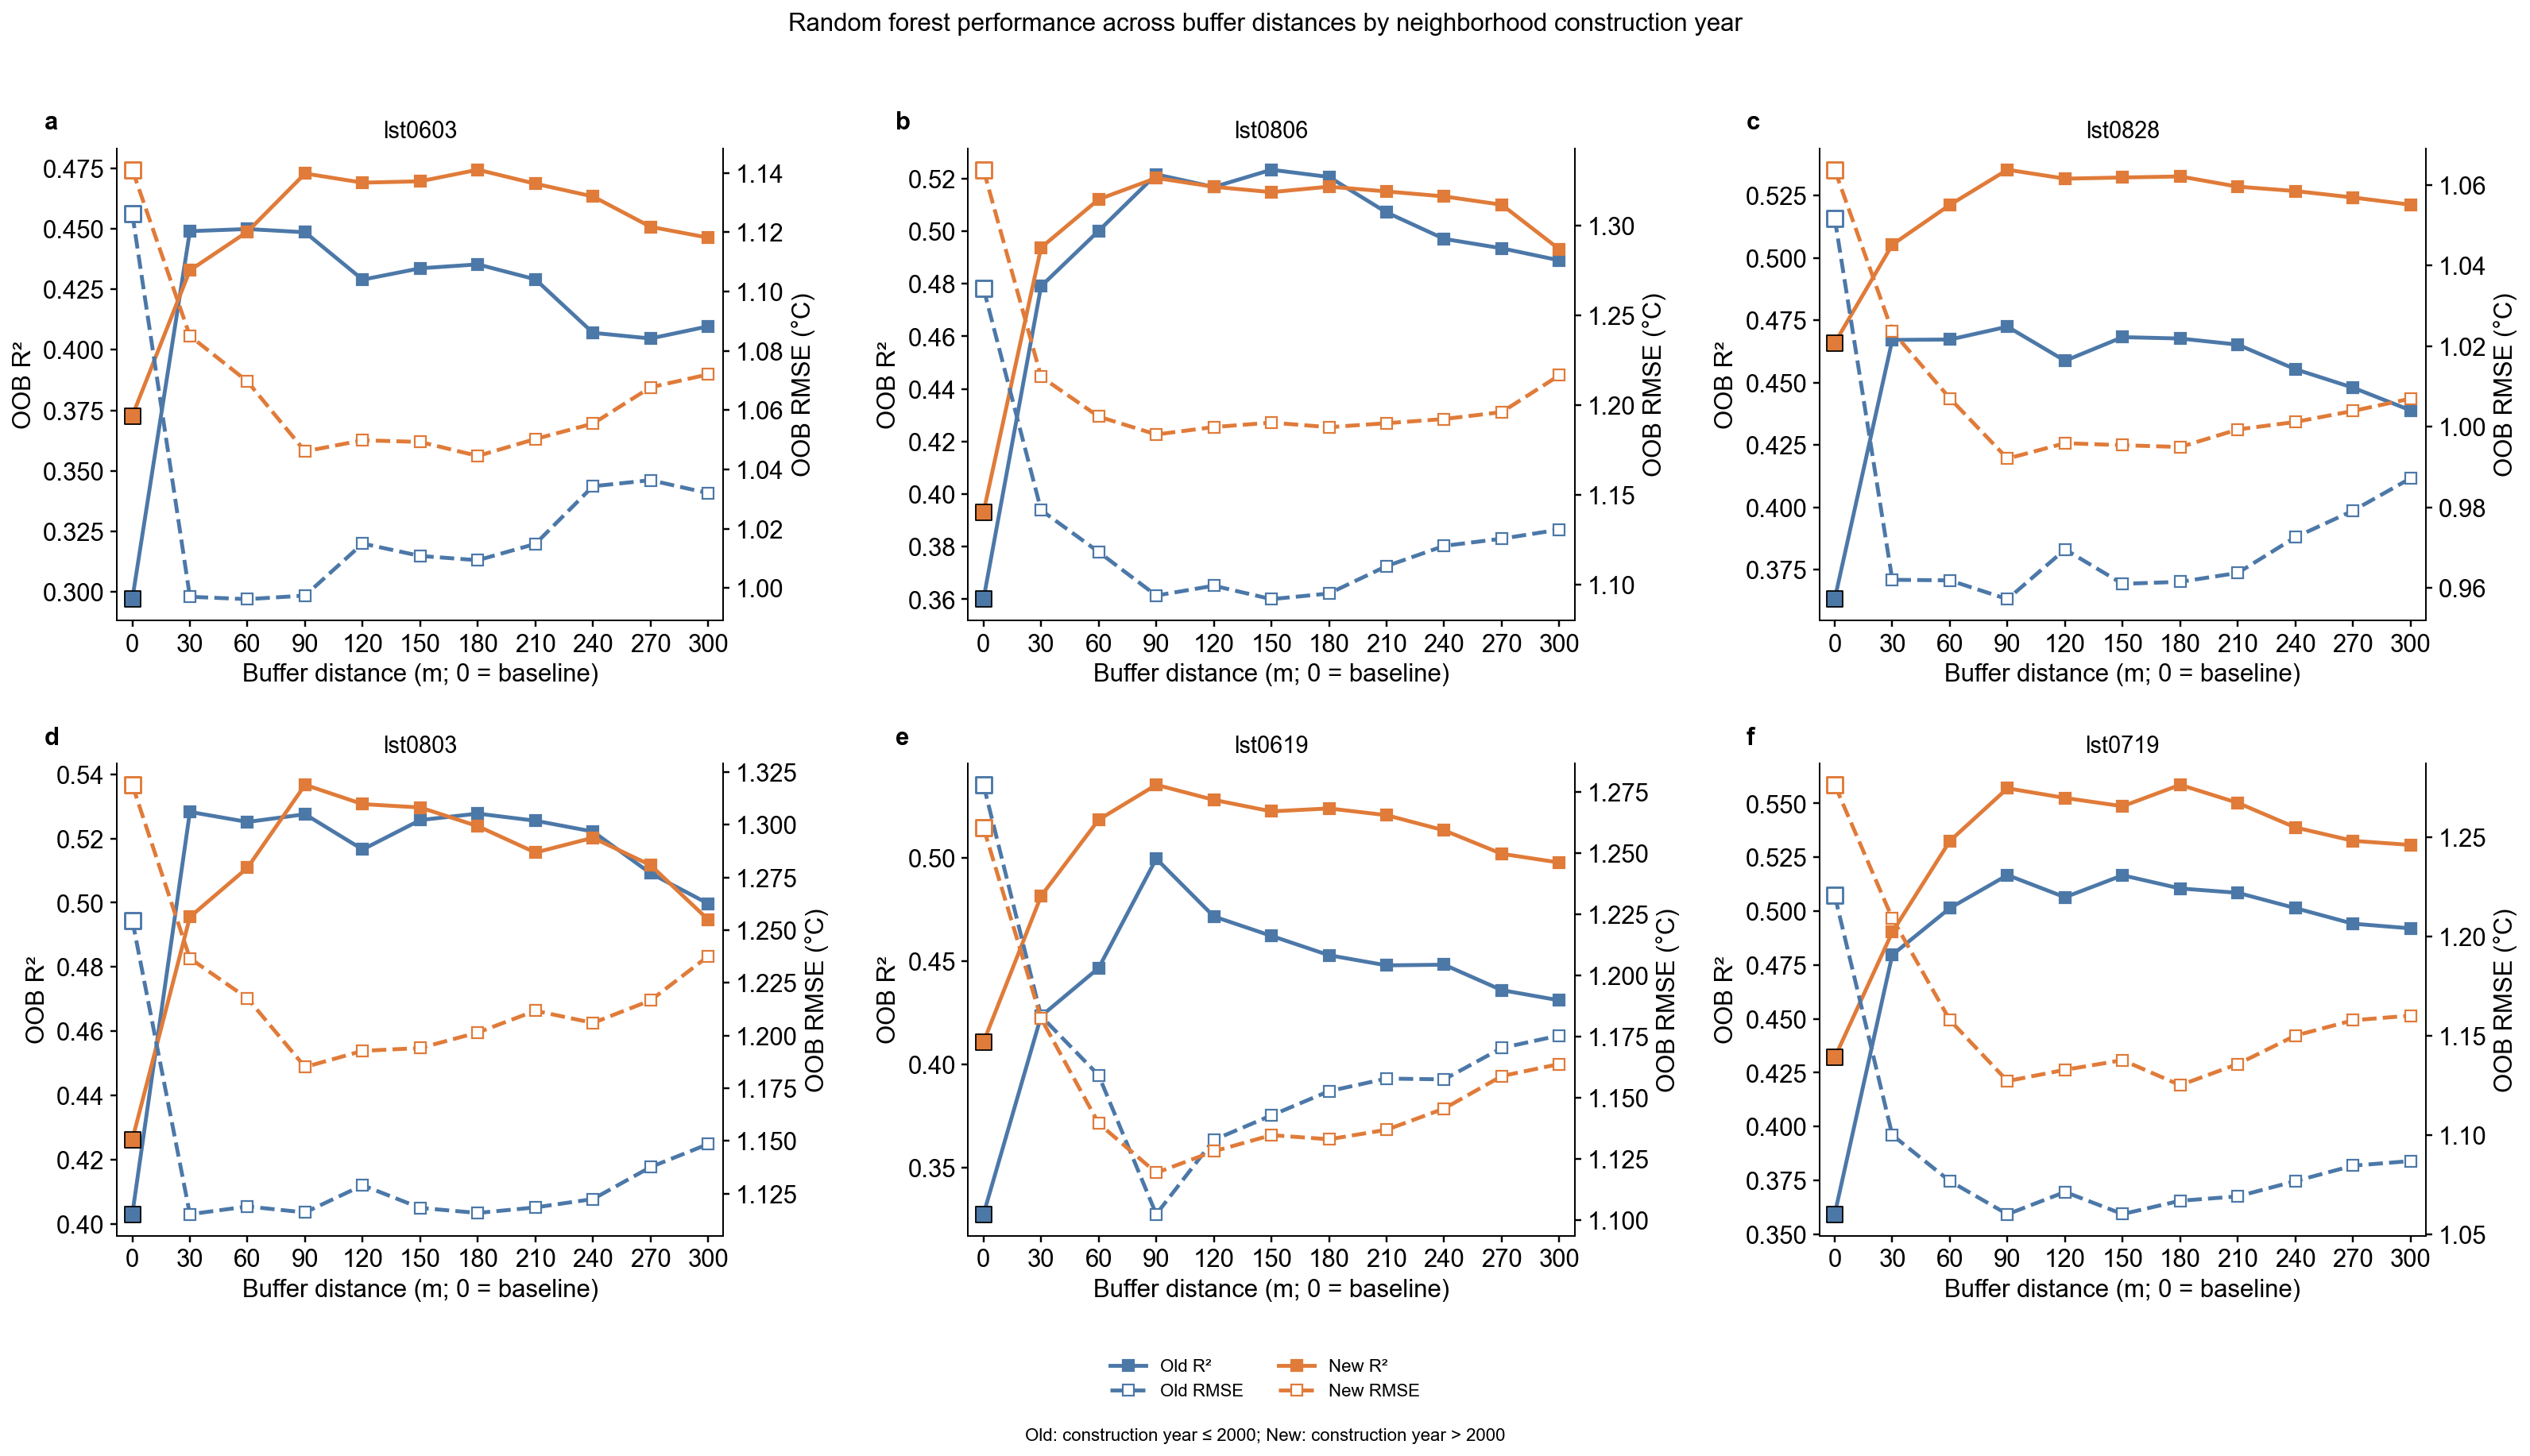

完成，共132个模型，用时3.7分钟。结果目录：E:\博士申请\第二篇论文\脚本\Python\construction_year_stratified_buffer_performance
各日期、各年份组在30–300m中最高OOB R²对应的缓冲距离：
 target year_group  buffer_distance_m  n_samples   r2_oob  rmse_oob
lst0603        Old                 60        467 0.449852  0.996235
lst0603        New                180        482 0.474337  1.044526
lst0619        Old                 90        467 0.499609  1.102444
lst0619        New                 90        482 0.535356  1.119404
lst0719        Old                 90        467 0.516737  1.060037
lst0719        New                180        482 0.558651  1.125036
lst0803        Old                 30        467 0.528291  1.115175
lst0803        New                 90        482 0.536738  1.185024
lst0806        Old                150        467 0.523370  1.091711
lst0806        New                 90        482 0.520222  1.183532
lst0828        Old                 90        467 0.472425  0.957212
lst0828        New                 90        482 0.535

In [2]:
%run "C:/Users/Y/Documents/Codex/2026-08-01/jin-ji/rf_oob_buffer_by_construction_year.py"

SyntaxError: (unicode error) 'unicodeescape' codec can't decode bytes in position 2-3: truncated \UXXXXXXXX escape (496888634.py, line 1)

In [3]:
# -*- coding: utf-8 -*-
"""
在面积大于10000 m²的社区中，比较 D_LST 的基线与30–300 m外围缓冲区模型，
并计算 OOB R² 与 OOB RMSE。

因变量
------
D_LST（热浪天气相对普通天气的社区升温，单位以源数据为准）

模型设置
--------
1. 基线模型（buffer distance = 0 m）：
   仅使用内部变量与控制变量，不加入任何缓冲区变量。

2. 缓冲区模型（buffer distance = 30–300 m，步长30 m）：
   使用内部变量、控制变量，以及相应距离的缓冲区变量。

固定变量（内部变量与控制变量）
----------------------------
TCC, GCI, BCI, WCI, RCI, Shape_Area,
jungong, BAH, BHSD, DIST

缓冲区变量
----------
TCC_bXm, GCI_bXm, BCI_bXm, WCI_bXm,
ISF_bXm, BAH_bXm, BHSD_bXm

说明
----
1. D_LST中的0是有效数值；仅删除缺失或非有限目标值；
2. 自变量缺失值用当前模型样本内的中位数填补；
3. 采用随机森林袋外预测（OOB prediction）计算R²和RMSE；
4. 基线模型以及每个缓冲距离模型均重新独立构建；
5. 输出全部模型结果、最佳模型结果、最佳缓冲区模型结果；
6. 输出一张 D_LST 的双y轴性能图；
7. 图中buffer distance = 0表示不包含缓冲区变量的基线模型。

首次运行若缺少依赖，可在Jupyter Notebook中执行：

!pip install pandas numpy scikit-learn matplotlib openpyxl xlrd
"""

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, r2_score


warnings.filterwarnings(
    "ignore",
    category=UserWarning,
)


# =============================================================================
# 0. 参数设置
# =============================================================================

DATA_PATH = Path(
    r"E:\博士申请\第二篇论文\data\wuhuanshiliang\SH_attributes_10000.xls"
)

OUTPUT_DIR = Path(
    r"E:\博士申请\第二篇论文\脚本\Python"
    r"\D_LST_multiscale_ISF_OOB"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# 因变量
TARGETS = ["D_LST"]


# 实际缓冲距离：30–300 m，每30 m一档
BUFFER_DISTANCES = list(
    range(30, 301, 30)
)


# 全部模型距离：
# 0 m表示不加入任何缓冲区变量的基线模型
MODEL_DISTANCES = [
    0,
    *BUFFER_DISTANCES,
]


# 固定变量：
# 内部变量 + 控制变量
FIXED_VARS = [
    "TCC",
    "GCI",
    "BCI",
    "WCI",
    "RCI",
    "Shape_Area",
    "jungong",
    "BAH",
    "BHSD",
    "DIST",
]


# 缓冲区变量的基础名称
BUFFER_BASE_VARS = [
    "TCC",
    "GCI",
    "BCI",
    "WCI",
    "ISF",
    "BAH",
    "BHSD",
]


# =============================================================================
# 随机森林参数
# =============================================================================

N_TREES = 1000

MIN_NODE_SIZE = 5

RANDOM_STATE = 42

N_JOBS = -1


# sklearn回归随机森林默认max_features=1.0，
# 即每次分裂考虑全部变量。
#
# 若希望采用更强的随机特征抽样，可改为：
# MAX_FEATURES = "sqrt"
#
# 或：
# MAX_FEATURES = 1 / 3

MAX_FEATURES = 1.0


# =============================================================================
# D_LST绘图参数
# =============================================================================

ORANGE_TARGETS = ["D_LST"]


GROUP_COLORS = {
    "orange": "#E69F00",
    "red": "#EA1818",
}


TARGET_MARKERS = {"D_LST": "s"}


# =============================================================================
# 字体与坐标轴参数
# =============================================================================

AXIS_LABEL_SIZE = 14

TICK_LABEL_SIZE = 14

TITLE_SIZE_SINGLE = 13

TITLE_SIZE_ALL = 14

LEGEND_SIZE_SINGLE = 11

LEGEND_SIZE_ALL = 10


# =============================================================================
# 1. 辅助函数
# =============================================================================

def get_buffer_vars(
    distance: int,
) -> list[str]:
    """
    生成指定距离对应的缓冲区变量名。

    当distance=0时，返回空列表，表示基线模型
    不包含任何缓冲区变量。

    例如
    ----
    distance=0：
        []

    distance=90：
        [
            "TCC_b90m",
            "GCI_b90m",
            "BCI_b90m",
            "WCI_b90m",
            "ISF_b90m",
            "BAH_b90m",
            "BHSD_b90m"
        ]
    """

    if distance == 0:
        return []

    if distance not in BUFFER_DISTANCES:
        raise ValueError(
            f"不支持的缓冲距离：{distance} m。"
            f"允许的距离为0或{BUFFER_DISTANCES}。"
        )

    return [
        f"{var}_b{distance}m"
        for var in BUFFER_BASE_VARS
    ]


def get_model_type(
    distance: int,
) -> str:
    """
    根据距离返回模型类型。

    0 m：
        Baseline

    30–300 m：
        Buffer
    """

    if distance == 0:
        return "Baseline"

    return "Buffer"


def validate_columns(
    df: pd.DataFrame,
) -> None:
    """
    一次性检查脚本所需字段是否全部存在。

    基线模型只检查TARGETS和FIXED_VARS；
    缓冲区模型检查30–300 m对应的缓冲区变量。
    """

    required = set(
        TARGETS + FIXED_VARS
    )

    # 这里只循环真实缓冲距离，不检查不存在的_b0m字段
    for distance in BUFFER_DISTANCES:
        required.update(
            get_buffer_vars(distance)
        )

    missing = sorted(
        required.difference(df.columns)
    )

    if missing:
        raise KeyError(
            "数据中缺少以下必要字段：\n"
            + "\n".join(missing)
        )


def fit_one_rf(
    df: pd.DataFrame,
    target: str,
    distance: int,
) -> dict:
    """
    针对一个因变量和一个模型距离构建随机森林模型，
    并返回OOB R²和OOB RMSE。

    distance=0：
        仅使用FIXED_VARS，作为基线模型。

    distance>0：
        使用FIXED_VARS和相应距离的缓冲区变量。
    """

    buffer_vars = get_buffer_vars(
        distance
    )

    predictors = (
        FIXED_VARS
        + buffer_vars
    )

    model_type = get_model_type(
        distance
    )

    model_df = df[
        [target] + predictors
    ].copy()


    # -------------------------------------------------------------------------
    # 将所有字段转为数值
    # -------------------------------------------------------------------------

    model_df = model_df.apply(
        pd.to_numeric,
        errors="coerce",
    )

    model_df.replace(
        [np.inf, -np.inf],
        np.nan,
        inplace=True,
    )


    # D_LST=0表示两种天气下无升温差异，应作为有效目标值保留。
    # 仅删除缺失或非有限的因变量。
    model_df = (
        model_df
        .dropna(subset=[target])
        .reset_index(drop=True)
    )


    if len(model_df) < 30:
        raise ValueError(
            f"{target}在{distance} m模型中"
            f"仅剩{len(model_df)}个有效样本，"
            f"无法稳定建模。"
        )


    # -------------------------------------------------------------------------
    # 提取自变量和因变量
    # -------------------------------------------------------------------------

    X = model_df[
        predictors
    ]

    y = model_df[
        target
    ].to_numpy(
        dtype=float
    )


    # -------------------------------------------------------------------------
    # 检查是否存在整列缺失
    # -------------------------------------------------------------------------

    all_missing_cols = (
        X.columns[
            X.isna().all()
        ]
        .tolist()
    )

    if all_missing_cols:
        raise ValueError(
            f"{target}–{distance} m模型"
            f"存在全为空的自变量："
            f"{all_missing_cols}"
        )


    # -------------------------------------------------------------------------
    # 中位数填补自变量缺失值
    # -------------------------------------------------------------------------

    imputer = SimpleImputer(
        strategy="median"
    )

    X_imputed = imputer.fit_transform(
        X
    )


    # -------------------------------------------------------------------------
    # 构建随机森林
    # -------------------------------------------------------------------------

    rf = RandomForestRegressor(
        n_estimators=N_TREES,
        min_samples_leaf=MIN_NODE_SIZE,
        max_features=MAX_FEATURES,
        bootstrap=True,
        oob_score=True,
        random_state=RANDOM_STATE,
        n_jobs=N_JOBS,
    )

    rf.fit(
        X_imputed,
        y,
    )


    # -------------------------------------------------------------------------
    # 提取OOB预测
    # -------------------------------------------------------------------------

    oob_pred = rf.oob_prediction_

    valid_oob = np.isfinite(
        oob_pred
    )

    if valid_oob.sum() == 0:
        raise RuntimeError(
            f"{target}–{distance} m模型"
            f"未生成有效OOB预测。"
        )


    # -------------------------------------------------------------------------
    # 计算OOB R²和OOB RMSE
    # -------------------------------------------------------------------------

    r2 = r2_score(
        y[valid_oob],
        oob_pred[valid_oob],
    )

    rmse = np.sqrt(
        mean_squared_error(
            y[valid_oob],
            oob_pred[valid_oob],
        )
    )


    return {
        "target": target,
        "model_type": model_type,
        "buffer_distance_m": distance,
        "n_samples": int(len(y)),
        "n_predictors": int(len(predictors)),
        "n_internal_control_vars": int(
            len(FIXED_VARS)
        ),
        "n_buffer_vars": int(
            len(buffer_vars)
        ),
        "r2_oob": float(r2),
        "rmse_oob": float(rmse),
        "n_trees": N_TREES,
        "min_node_size": MIN_NODE_SIZE,
        "max_features": str(MAX_FEATURES),
    }


def style_axes(
    ax1: plt.Axes,
    ax2=None,
) -> None:
    """
    统一设置横轴、左侧纵轴和右侧纵轴格式。

    横轴中的0表示基线模型。
    """

    # -------------------------------------------------------------------------
    # 左侧坐标轴和横轴
    # -------------------------------------------------------------------------

    ax1.spines["top"].set_visible(
        False
    )

    ax1.tick_params(
        axis="both",
        direction="out",
        width=1.1,
        labelsize=TICK_LABEL_SIZE,
    )

    # 包括0 m基线模型
    ax1.set_xticks(
        MODEL_DISTANCES
    )

    ax1.set_xlim(
        min(MODEL_DISTANCES) - 8,
        max(MODEL_DISTANCES) + 8,
    )


    # -------------------------------------------------------------------------
    # 右侧纵轴
    # -------------------------------------------------------------------------

    if ax2 is not None:

        ax2.spines["top"].set_visible(
            False
        )

        ax2.tick_params(
            axis="y",
            direction="out",
            width=1.1,
            labelsize=TICK_LABEL_SIZE,
        )


def get_target_color(
    target: str,
) -> str:
    """
    根据目标变量所属分组返回绘图颜色。
    """

    if target in ORANGE_TARGETS:
        return GROUP_COLORS["orange"]

    return GROUP_COLORS["red"]


# =============================================================================
# 2. 单场景绘图
# =============================================================================

def plot_single_target(
    results: pd.DataFrame,
    target: str,
) -> None:
    """
    为 D_LST 绘制R²与RMSE双y轴折线图。

    横轴0表示仅包含内部变量和控制变量的基线模型。
    """

    sub = (
        results.loc[
            results["target"] == target
        ]
        .sort_values(
            "buffer_distance_m"
        )
        .copy()
    )


    color = get_target_color(
        target
    )

    marker = TARGET_MARKERS[
        target
    ]


    # -------------------------------------------------------------------------
    # 创建双y轴图
    # -------------------------------------------------------------------------

    fig, ax1 = plt.subplots(
        figsize=(8.6, 5.6),
        dpi=160,
    )

    ax2 = ax1.twinx()


    # -------------------------------------------------------------------------
    # 左轴：OOB R²
    # -------------------------------------------------------------------------

    line_r2 = ax1.plot(
        sub["buffer_distance_m"],
        sub["r2_oob"],
        color=color,
        linestyle="-",
        marker=marker,
        linewidth=2.2,
        markersize=6,
        label=f"{target} R²",
    )[0]


    # -------------------------------------------------------------------------
    # 右轴：OOB RMSE
    # -------------------------------------------------------------------------

    line_rmse = ax2.plot(
        sub["buffer_distance_m"],
        sub["rmse_oob"],
        color=color,
        linestyle="--",
        marker=marker,
        linewidth=2.2,
        markersize=6,
        markerfacecolor="white",
        label=f"{target} RMSE",
    )[0]


    # -------------------------------------------------------------------------
    # 突出显示0 m基线模型
    # -------------------------------------------------------------------------

    baseline = sub.loc[
        sub["buffer_distance_m"] == 0
    ]

    if not baseline.empty:

        ax1.scatter(
            baseline["buffer_distance_m"],
            baseline["r2_oob"],
            color=color,
            marker=marker,
            s=75,
            edgecolor="black",
            linewidth=0.8,
            zorder=10,
        )

        ax2.scatter(
            baseline["buffer_distance_m"],
            baseline["rmse_oob"],
            facecolor="white",
            edgecolor=color,
            marker=marker,
            s=75,
            linewidth=1.3,
            zorder=10,
        )


    # -------------------------------------------------------------------------
    # 坐标轴标题和图标题
    # -------------------------------------------------------------------------

    ax1.set_xlabel(
        "Buffer distance (m; 0 = baseline)",
        fontsize=AXIS_LABEL_SIZE,
    )

    ax1.set_ylabel(
        "OOB R²",
        fontsize=AXIS_LABEL_SIZE,
    )

    ax2.set_ylabel(
        "OOB RMSE (°C)",
        fontsize=AXIS_LABEL_SIZE,
    )

    ax1.set_title(
        f"RF performance across buffer distances: {target}",
        fontsize=TITLE_SIZE_SINGLE,
    )


    # -------------------------------------------------------------------------
    # 统一设置左右坐标轴
    # -------------------------------------------------------------------------

    style_axes(
        ax1,
        ax2,
    )


    # -------------------------------------------------------------------------
    # 图例
    # -------------------------------------------------------------------------

    ax1.legend(
        [
            line_r2,
            line_rmse,
        ],
        [
            line_r2.get_label(),
            line_rmse.get_label(),
        ],
        loc="best",
        frameon=False,
        fontsize=LEGEND_SIZE_SINGLE,
    )


    # -------------------------------------------------------------------------
    # 保存图片
    # -------------------------------------------------------------------------

    fig.tight_layout()

    fig.savefig(
        OUTPUT_DIR
        / f"RF_{target}_R2_RMSE_dual_axis_with_baseline.png",
        dpi=600,
        bbox_inches="tight",
    )

    fig.savefig(
        OUTPUT_DIR
        / f"RF_{target}_R2_RMSE_dual_axis_with_baseline.pdf",
        bbox_inches="tight",
    )

    plt.close(fig)


# =============================================================================
# 3. 主程序
# =============================================================================

def main() -> None:
    """
    主程序：
    读取数据、构建基线及缓冲区模型、输出结果并绘图。
    """

    print(
        f"正在读取数据：{DATA_PATH}"
    )


    # -------------------------------------------------------------------------
    # 读取数据
    # -------------------------------------------------------------------------

    df = pd.read_excel(
        DATA_PATH,
        sheet_name=0,
        engine="xlrd",
    )


    print(
        f"数据维度："
        f"{df.shape[0]}行 × "
        f"{df.shape[1]}列"
    )


    # -------------------------------------------------------------------------
    # 检查字段
    # -------------------------------------------------------------------------

    validate_columns(
        df
    )

    print(
        "字段检查通过。"
    )


    # -------------------------------------------------------------------------
    # 循环构建模型
    # -------------------------------------------------------------------------

    all_results = []

    total_models = (
        len(TARGETS)
        * len(MODEL_DISTANCES)
    )

    model_no = 0


    for target in TARGETS:

        for distance in MODEL_DISTANCES:

            model_no += 1

            model_type = get_model_type(
                distance
            )

            if distance == 0:
                model_description = (
                    "baseline（仅内部变量与控制变量）"
                )
            else:
                model_description = (
                    f"{distance} m缓冲区模型"
                )


            print(
                f"[{model_no:02d}/{total_models}] "
                f"建模："
                f"target={target}, "
                f"model={model_description}"
            )


            result = fit_one_rf(
                df=df,
                target=target,
                distance=distance,
            )


            all_results.append(
                result
            )


            print(
                f"    type={model_type}, "
                f"n={result['n_samples']}, "
                f"predictors={result['n_predictors']}, "
                f"OOB R²={result['r2_oob']:.4f}, "
                f"OOB RMSE={result['rmse_oob']:.4f}"
            )


    # -------------------------------------------------------------------------
    # 整理全部结果
    # -------------------------------------------------------------------------

    results = pd.DataFrame(
        all_results
    )

    results = (
        results
        .sort_values(
            [
                "target",
                "buffer_distance_m",
            ]
        )
        .reset_index(drop=True)
    )


    # -------------------------------------------------------------------------
    # 提取基线模型结果
    # -------------------------------------------------------------------------

    baseline_results = (
        results.loc[
            results["buffer_distance_m"] == 0
        ]
        .sort_values("target")
        .reset_index(drop=True)
    )


    # -------------------------------------------------------------------------
    # 仅保留30–300 m缓冲区模型
    # -------------------------------------------------------------------------

    buffer_results = (
        results.loc[
            results["buffer_distance_m"] > 0
        ]
        .copy()
    )


    # -------------------------------------------------------------------------
    # 在所有模型中按最高R²提取最优模型
    # -------------------------------------------------------------------------

    best_by_r2 = (
        results.loc[
            results
            .groupby("target")["r2_oob"]
            .idxmax()
        ]
        .sort_values("target")
        .reset_index(drop=True)
    )


    # -------------------------------------------------------------------------
    # 在所有模型中按最低RMSE提取最优模型
    # -------------------------------------------------------------------------

    best_by_rmse = (
        results.loc[
            results
            .groupby("target")["rmse_oob"]
            .idxmin()
        ]
        .sort_values("target")
        .reset_index(drop=True)
    )


    # -------------------------------------------------------------------------
    # 仅在30–300 m模型中按最高R²提取最佳缓冲距离
    # -------------------------------------------------------------------------

    best_buffer_by_r2 = (
        buffer_results.loc[
            buffer_results
            .groupby("target")["r2_oob"]
            .idxmax()
        ]
        .sort_values("target")
        .reset_index(drop=True)
    )


    # -------------------------------------------------------------------------
    # 仅在30–300 m模型中按最低RMSE提取最佳缓冲距离
    # -------------------------------------------------------------------------

    best_buffer_by_rmse = (
        buffer_results.loc[
            buffer_results
            .groupby("target")["rmse_oob"]
            .idxmin()
        ]
        .sort_values("target")
        .reset_index(drop=True)
    )


    # -------------------------------------------------------------------------
    # 计算最佳缓冲区模型相对于基线模型的性能变化
    # -------------------------------------------------------------------------

    baseline_compare = baseline_results[
        [
            "target",
            "r2_oob",
            "rmse_oob",
        ]
    ].rename(
        columns={
            "r2_oob": "baseline_r2_oob",
            "rmse_oob": "baseline_rmse_oob",
        }
    )

    best_buffer_comparison = (
        best_buffer_by_r2.merge(
            baseline_compare,
            on="target",
            how="left",
        )
    )

    best_buffer_comparison[
        "delta_r2_vs_baseline"
    ] = (
        best_buffer_comparison["r2_oob"]
        - best_buffer_comparison["baseline_r2_oob"]
    )

    best_buffer_comparison[
        "delta_rmse_vs_baseline"
    ] = (
        best_buffer_comparison["rmse_oob"]
        - best_buffer_comparison["baseline_rmse_oob"]
    )


    # -------------------------------------------------------------------------
    # 输出路径
    # -------------------------------------------------------------------------

    csv_path = (
        OUTPUT_DIR
        / "RF_buffer_distance_metrics_with_baseline.csv"
    )

    xlsx_path = (
        OUTPUT_DIR
        / "RF_buffer_distance_metrics_with_baseline.xlsx"
    )


    # -------------------------------------------------------------------------
    # 保存CSV
    # -------------------------------------------------------------------------

    results.to_csv(
        csv_path,
        index=False,
        encoding="utf-8-sig",
    )


    # -------------------------------------------------------------------------
    # 保存Excel
    # -------------------------------------------------------------------------

    with pd.ExcelWriter(
        xlsx_path,
        engine="openpyxl",
    ) as writer:

        results.to_excel(
            writer,
            sheet_name="all_metrics",
            index=False,
        )

        baseline_results.to_excel(
            writer,
            sheet_name="baseline_models",
            index=False,
        )

        buffer_results.to_excel(
            writer,
            sheet_name="buffer_models",
            index=False,
        )

        best_by_r2.to_excel(
            writer,
            sheet_name="best_all_by_R2",
            index=False,
        )

        best_by_rmse.to_excel(
            writer,
            sheet_name="best_all_by_RMSE",
            index=False,
        )

        best_buffer_by_r2.to_excel(
            writer,
            sheet_name="best_buffer_by_R2",
            index=False,
        )

        best_buffer_by_rmse.to_excel(
            writer,
            sheet_name="best_buffer_by_RMSE",
            index=False,
        )

        best_buffer_comparison.to_excel(
            writer,
            sheet_name="buffer_vs_baseline",
            index=False,
        )


    # -------------------------------------------------------------------------
    # 绘制 D_LST 的单场景图
    # -------------------------------------------------------------------------

    for target in TARGETS:

        plot_single_target(
            results,
            target,
        )


    # -------------------------------------------------------------------------
    # 输出运行结果
    # -------------------------------------------------------------------------

    print(
        "\n全部模型计算完成。"
    )

    print(
        f"结果表：{xlsx_path}"
    )

    print(
        "D_LST性能图："
        f"{OUTPUT_DIR / 'RF_D_LST_R2_RMSE_dual_axis_with_baseline.png'}"
    )


    print(
        "\n各场景基线模型性能："
    )

    print(
        baseline_results[
            [
                "target",
                "buffer_distance_m",
                "n_predictors",
                "r2_oob",
                "rmse_oob",
            ]
        ].to_string(
            index=False
        )
    )


    print(
        "\n各场景在所有模型中最高OOB R²对应的模型："
    )

    print(
        best_by_r2[
            [
                "target",
                "model_type",
                "buffer_distance_m",
                "r2_oob",
                "rmse_oob",
            ]
        ].to_string(
            index=False
        )
    )


    print(
        "\n各场景在30–300 m中最高OOB R²对应的缓冲距离："
    )

    print(
        best_buffer_by_r2[
            [
                "target",
                "buffer_distance_m",
                "r2_oob",
                "rmse_oob",
            ]
        ].to_string(
            index=False
        )
    )


    print(
        "\n最佳缓冲区模型相对于基线模型的性能变化："
    )

    print(
        best_buffer_comparison[
            [
                "target",
                "buffer_distance_m",
                "baseline_r2_oob",
                "r2_oob",
                "delta_r2_vs_baseline",
                "baseline_rmse_oob",
                "rmse_oob",
                "delta_rmse_vs_baseline",
            ]
        ].to_string(
            index=False
        )
    )


# =============================================================================
# 5. 运行主程序
# =============================================================================

if __name__ == "__main__":
    main()


正在读取数据：E:\博士申请\第二篇论文\data\wuhuanshiliang\SH_attributes_10000.xls
数据维度：949行 × 167列
字段检查通过。
[01/11] 建模：target=D_LST, model=baseline（仅内部变量与控制变量）
    type=Baseline, n=949, predictors=10, OOB R²=0.3109, OOB RMSE=0.6123
[02/11] 建模：target=D_LST, model=30 m缓冲区模型
    type=Buffer, n=949, predictors=17, OOB R²=0.3434, OOB RMSE=0.5977
[03/11] 建模：target=D_LST, model=60 m缓冲区模型
    type=Buffer, n=949, predictors=17, OOB R²=0.3492, OOB RMSE=0.5950
[04/11] 建模：target=D_LST, model=90 m缓冲区模型
    type=Buffer, n=949, predictors=17, OOB R²=0.3500, OOB RMSE=0.5946
[05/11] 建模：target=D_LST, model=120 m缓冲区模型
    type=Buffer, n=949, predictors=17, OOB R²=0.3550, OOB RMSE=0.5924
[06/11] 建模：target=D_LST, model=150 m缓冲区模型
    type=Buffer, n=949, predictors=17, OOB R²=0.3662, OOB RMSE=0.5872
[07/11] 建模：target=D_LST, model=180 m缓冲区模型
    type=Buffer, n=949, predictors=17, OOB R²=0.3763, OOB RMSE=0.5825
[08/11] 建模：target=D_LST, model=210 m缓冲区模型
    type=Buffer, n=949, predictors=17, OOB R²=0.3812, OOB RMSE=0.5802
[09/1

In [1]:
# -*- coding: utf-8 -*-
"""D_LST 多尺度随机森林：按竣工年份分别拟合老旧与新建社区。

沿用原 D_LST 脚本的固定随机森林参数、内部变量、外围 ISF 变量、
0–300 m 尺度和 OOB 评价方法。老旧社区为 jungong <= 2000，
新建社区为 jungong > 2000。D_LST=0 是有效观测值。

在 Jupyter 中运行：%run "RF_D_LST_ISF_old_new_OOB.py"
"""

from pathlib import Path
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, r2_score


DATA_PATH = Path(
    r"E:\博士申请\第二篇论文\data\wuhuanshiliang\SH_attributes_10000.xls"
)
OUTPUT_DIR = Path(os.environ.get(
    "RF_OUTPUT_DIR",
    r"E:\博士申请\第二篇论文\脚本\Python\D_LST_ISF_old_new_OOB",
))

TARGET = "D_LST"
AREA_COLUMN = "Shape_Area"
YEAR_COLUMN = "jungong"
YEAR_CUTOFF = 2000
MIN_AREA_M2 = 10000.0
DISTANCES = [0, *range(30, 301, 30)]

# 与原脚本一致：内部 RCI 保留，外围 RCI 替换为 ISF。
FIXED_VARS = [
    "TCC", "GCI", "BCI", "WCI", "RCI", "Shape_Area",
    "jungong", "BAH", "BHSD", "DIST",
]
BUFFER_BASE_VARS = ["TCC", "GCI", "BCI", "WCI", "ISF", "BAH", "BHSD"]

N_TREES = 1000
MIN_NODE_SIZE = 5
MAX_FEATURES = 1.0
RANDOM_STATE = 42
N_JOBS = -1

GROUP_ORDER = ["Old", "New"]
GROUP_COLORS = {"Old": "#4472A5", "New": "#E07A52"}


def predictors_for_distance(distance: int) -> list[str]:
    if distance not in DISTANCES:
        raise ValueError(f"不支持缓冲距离：{distance}")
    if distance == 0:
        return FIXED_VARS.copy()
    return FIXED_VARS + [f"{v}_b{distance}m" for v in BUFFER_BASE_VARS]


def load_data() -> tuple[pd.DataFrame, pd.DataFrame]:
    if not DATA_PATH.is_file():
        raise FileNotFoundError(f"找不到输入数据：{DATA_PATH}")
    raw = pd.read_excel(DATA_PATH, sheet_name=0, engine="xlrd")
    required = list(dict.fromkeys(
        [TARGET, AREA_COLUMN, YEAR_COLUMN]
        + [v for d in DISTANCES for v in predictors_for_distance(d)]
    ))
    missing_columns = sorted(set(required).difference(raw.columns))
    if missing_columns:
        raise KeyError(f"缺少字段：{missing_columns}")

    data = raw[required].apply(pd.to_numeric, errors="coerce")
    data = data.replace([np.inf, -np.inf], np.nan)
    # 仅目标、面积及竣工年份缺失时剔除；D_LST=0 不剔除。
    eligible = (
        data[TARGET].notna()
        & data[AREA_COLUMN].gt(MIN_AREA_M2)
        & data[YEAR_COLUMN].notna()
    )
    data = data.loc[eligible].copy()
    data["Year_Group"] = np.where(
        data[YEAR_COLUMN].le(YEAR_CUTOFF), "Old", "New"
    )
    if data.empty:
        raise ValueError("面积和目标变量筛选后没有社区。")

    summary = data.groupby("Year_Group", sort=False).agg(
        n_communities=(TARGET, "size"),
        year_min=(YEAR_COLUMN, "min"),
        year_max=(YEAR_COLUMN, "max"),
        D_LST_mean=(TARGET, "mean"),
        D_LST_sd=(TARGET, "std"),
    ).reset_index()
    summary["Year_Group"] = pd.Categorical(
        summary["Year_Group"], categories=GROUP_ORDER, ordered=True
    )
    summary = summary.sort_values("Year_Group").reset_index(drop=True)
    if set(summary["Year_Group"].astype(str)) != set(GROUP_ORDER):
        raise ValueError("老旧／新建社区中有一组无样本。")
    return data, summary


def fit_one_model(group_data: pd.DataFrame, group: str, distance: int) -> dict:
    predictors = predictors_for_distance(distance)
    X = group_data[predictors]
    y = group_data[TARGET].to_numpy(dtype=float)
    if len(y) < 30:
        raise ValueError(f"{group} 社区只有 {len(y)} 个样本。")
    empty = X.columns[X.isna().all()].tolist()
    if empty:
        raise ValueError(f"{group}，{distance} m：自变量整列缺失 {empty}")

    # 与原脚本一致。当前数据的这些字段均无缺失，因此不会改变 X。
    X_imputed = SimpleImputer(strategy="median").fit_transform(X)
    rf = RandomForestRegressor(
        n_estimators=N_TREES,
        min_samples_leaf=MIN_NODE_SIZE,
        max_features=MAX_FEATURES,
        bootstrap=True,
        oob_score=True,
        random_state=RANDOM_STATE,
        n_jobs=N_JOBS,
    )
    rf.fit(X_imputed, y)
    oob = rf.oob_prediction_
    valid = np.isfinite(oob)
    if valid.sum() < 2:
        raise RuntimeError(f"{group}，{distance} m：有效 OOB 预测不足。")
    return {
        "Year_Group": group,
        "target": TARGET,
        "buffer_distance_m": distance,
        "model_type": "baseline" if distance == 0 else "buffer",
        "n_samples": len(y),
        "n_predictors": len(predictors),
        "target_sd": float(np.std(y, ddof=1)),
        "r2_oob": float(r2_score(y[valid], oob[valid])),
        "rmse_oob": float(np.sqrt(mean_squared_error(y[valid], oob[valid]))),
        "n_trees": N_TREES,
        "min_node_size": MIN_NODE_SIZE,
        "max_features": MAX_FEATURES,
    }


def add_baseline_comparison(results: pd.DataFrame) -> pd.DataFrame:
    baseline = results.loc[results["buffer_distance_m"].eq(0), [
        "Year_Group", "r2_oob", "rmse_oob",
    ]].rename(columns={
        "r2_oob": "baseline_r2_oob",
        "rmse_oob": "baseline_rmse_oob",
    })
    out = results.merge(baseline, on="Year_Group", how="left", validate="many_to_one")
    out["delta_r2_vs_baseline"] = out["r2_oob"] - out["baseline_r2_oob"]
    out["delta_rmse_vs_baseline"] = out["rmse_oob"] - out["baseline_rmse_oob"]
    return out


def plot_results(results: pd.DataFrame, output_dir: Path) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), sharex=True, dpi=160)
    r2_lim = results["r2_oob"].agg(["min", "max"])
    rmse_lim = results["rmse_oob"].agg(["min", "max"])
    r2_pad = max(0.02, (r2_lim["max"] - r2_lim["min"]) * 0.12)
    rmse_pad = max(0.02, (rmse_lim["max"] - rmse_lim["min"]) * 0.12)

    for ax, group in zip(axes, GROUP_ORDER):
        sub = results.loc[results["Year_Group"].eq(group)].sort_values("buffer_distance_m")
        color = GROUP_COLORS[group]
        right = ax.twinx()
        line_r2, = ax.plot(
            sub["buffer_distance_m"], sub["r2_oob"],
            color=color, marker="s", linewidth=2, label="OOB R²",
        )
        line_rmse, = right.plot(
            sub["buffer_distance_m"], sub["rmse_oob"],
            color=color, marker="s", markerfacecolor="white",
            linestyle="--", linewidth=2, label="OOB RMSE",
        )
        ax.set_title(f"{group} neighborhoods (n={int(sub['n_samples'].iloc[0])})")
        ax.set_xlabel("Buffer distance (m; 0 = baseline)")
        ax.set_ylabel("OOB R²")
        right.set_ylabel("OOB RMSE (°C)")
        ax.set_xticks(DISTANCES)
        ax.set_ylim(r2_lim["min"] - r2_pad, r2_lim["max"] + r2_pad)
        right.set_ylim(rmse_lim["min"] - rmse_pad, rmse_lim["max"] + rmse_pad)
        ax.grid(axis="y", alpha=0.25)
        ax.spines["top"].set_visible(False)
        right.spines["top"].set_visible(False)
        ax.legend([line_r2, line_rmse], ["OOB R²", "OOB RMSE"], frameon=False)

    fig.suptitle("D_LST prediction across buffer distances by construction-year group")
    fig.tight_layout()
    fig.savefig(output_dir / "D_LST_ISF_old_new_OOB_2panel.png", dpi=600, bbox_inches="tight")
    fig.savefig(output_dir / "D_LST_ISF_old_new_OOB_2panel.pdf", bbox_inches="tight")
    plt.close(fig)


def main() -> tuple[pd.DataFrame, pd.DataFrame]:
    data, group_summary = load_data()
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    print(group_summary.to_string(index=False))

    rows = []
    total = len(GROUP_ORDER) * len(DISTANCES)
    for group in GROUP_ORDER:
        subset = data.loc[data["Year_Group"].eq(group)]
        for distance in DISTANCES:
            print(f"[{len(rows) + 1}/{total}] {group}, {distance} m", flush=True)
            rows.append(fit_one_model(subset, group, distance))

    results = add_baseline_comparison(pd.DataFrame(rows))
    buffer_only = results.loc[results["buffer_distance_m"].gt(0)].copy()
    best_by_r2 = buffer_only.loc[
        buffer_only.groupby("Year_Group")["r2_oob"].idxmax()
    ].sort_values("Year_Group").reset_index(drop=True)
    best_by_rmse = buffer_only.loc[
        buffer_only.groupby("Year_Group")["rmse_oob"].idxmin()
    ].sort_values("Year_Group").reset_index(drop=True)

    results.to_csv(OUTPUT_DIR / "D_LST_ISF_old_new_all_distances.csv", index=False, encoding="utf-8-sig")
    with pd.ExcelWriter(OUTPUT_DIR / "D_LST_ISF_old_new_OOB_results.xlsx", engine="openpyxl") as writer:
        group_summary.to_excel(writer, sheet_name="Group_summary", index=False)
        results.to_excel(writer, sheet_name="All_distances", index=False)
        best_by_r2.to_excel(writer, sheet_name="Best_buffer_by_R2", index=False)
        best_by_rmse.to_excel(writer, sheet_name="Best_buffer_by_RMSE", index=False)
    plot_results(results, OUTPUT_DIR)

    print("\n各组最高 OOB R2 所对应的缓冲距离：")
    print(best_by_r2[[
        "Year_Group", "buffer_distance_m", "n_samples", "r2_oob",
        "rmse_oob", "delta_r2_vs_baseline", "delta_rmse_vs_baseline",
    ]].to_string(index=False))
    print(f"\n结果目录：{OUTPUT_DIR}")
    return results, group_summary


if __name__ == "__main__":
    main()


Year_Group  n_communities  year_min  year_max  D_LST_mean  D_LST_sd
       Old            467      1955      2000   11.258856  0.738667
       New            482      2001      2020   10.865395  0.684365
[1/22] Old, 0 m
[2/22] Old, 30 m
[3/22] Old, 60 m
[4/22] Old, 90 m
[5/22] Old, 120 m
[6/22] Old, 150 m
[7/22] Old, 180 m
[8/22] Old, 210 m
[9/22] Old, 240 m
[10/22] Old, 270 m
[11/22] Old, 300 m
[12/22] New, 0 m
[13/22] New, 30 m
[14/22] New, 60 m
[15/22] New, 90 m
[16/22] New, 120 m
[17/22] New, 150 m
[18/22] New, 180 m
[19/22] New, 210 m
[20/22] New, 240 m
[21/22] New, 270 m
[22/22] New, 300 m

各组最高 OOB R2 所对应的缓冲距离：
Year_Group  buffer_distance_m  n_samples   r2_oob  rmse_oob  delta_r2_vs_baseline  delta_rmse_vs_baseline
       New                300        482 0.264099  0.586471              0.074662               -0.029032
       Old                240        467 0.380310  0.580859              0.099573               -0.044929

结果目录：E:\博士申请\第二篇论文\脚本\Python\D_LST_ISF_old_new_OOB


In [ ]:
# -*- coding: utf-8 -*-
"""
GWRF: lst0603与lst0619；无缓冲区基线 + 30–300 m缓冲区模型。
坐标：CENT_X、CENT_Y，WGS 84 / UTM zone 50N，米（EPSG:32650）。
输入已投影，不重复投影。请确认数据属性确实对应此坐标系。
实现：自适应K近邻、bi-square权重、均匀bootstrap、加权树分裂。
评价：每个焦点仅由其局部森林中未抽中它的树预测，再汇总OOB R²/RMSE。
这不是SpatialML的逐数值复现；不是空间独立验证，也不保存所有局部森林。
依赖：pip install "scikit-learn>=1.4,<1.9" pandas numpy scipy matplotlib openpyxl xlrd
BW_NEIGHBORS=500为待验证起点，不是已优化带宽。计算量约22*N个局部森林。
仅把y=0视为缺失；删除y或坐标无效行；X缺失用局部非焦点样本中位数填补。
"""

from pathlib import Path
import warnings

import sklearn
from scipy.spatial import cKDTree

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, r2_score




# =============================================================================
# 0. 参数设置
# =============================================================================

DATA_PATH = Path(
    r"E:\博士申请\第二篇论文\data\wuhuanshiliang\SH_attributes_10000.xls"
)

OUTPUT_DIR = Path(
    r"E:\excel\FILES\博士申请\第二篇论文"
    r"\脚本\Python"
)

OUTPUT_DIR = OUTPUT_DIR / "GWRF_results"


# 因变量
TARGETS = ["lst0603", "lst0619"]

# 自适应带宽：邻域内样本数，包含焦点；与30–300 m缓冲距离不同。
COORD_COLS = ["CENT_X", "CENT_Y"]
BW_NEIGHBORS = 250
MIN_OOB_TREES = 20


# 实际缓冲距离：30–300 m，每30 m一档
BUFFER_DISTANCES = list(
    range(30, 301, 30)
)


# 全部模型距离：
# 0 m表示不加入任何缓冲区变量的基线模型
MODEL_DISTANCES = [
    0,
    *BUFFER_DISTANCES,
]


# 固定变量：
# 内部变量 + 控制变量
FIXED_VARS = [
    "TCC",
    "GCI",
    "BCI",
    "WCI",
    "RCI",
    "Shape_Area",
    "jungong",
    "BAH",
    "BHSD",
    "DIST",
]


# 缓冲区变量的基础名称
BUFFER_BASE_VARS = [
    "TCC",
    "GCI",
    "BCI",
    "WCI",
    "RCI",
    "BAH",
    "BHSD",
]


# =============================================================================
# 随机森林参数
# =============================================================================

N_TREES = 100

MIN_NODE_SIZE = 5

RANDOM_STATE = 42

N_JOBS = -1


# sklearn回归随机森林默认max_features=1.0，
# 即每次分裂考虑全部变量。
#
# 若希望采用更强的随机特征抽样，可改为：
# MAX_FEATURES = "sqrt"
#
# 或：
# MAX_FEATURES = 1 / 3

MAX_FEATURES = 1.0


# =============================================================================
# 场景分组和绘图参数
# =============================================================================

ORANGE_TARGETS = ["lst0603"]

RED_TARGETS = ["lst0619"]


GROUP_COLORS = {
    "orange": "#E69F00",
    "red": "#EA1818",
}


TARGET_MARKERS = {"lst0603": "o", "lst0619": "s"}


# =============================================================================
# 字体与坐标轴参数
# =============================================================================

AXIS_LABEL_SIZE = 14

TICK_LABEL_SIZE = 14

TITLE_SIZE_SINGLE = 13

TITLE_SIZE_ALL = 14

LEGEND_SIZE_SINGLE = 11

LEGEND_SIZE_ALL = 10


# =============================================================================
# 1. 辅助函数
# =============================================================================

def get_buffer_vars(
    distance: int,
) -> list[str]:
    """
    生成指定距离对应的缓冲区变量名。

    当distance=0时，返回空列表，表示基线模型
    不包含任何缓冲区变量。

    例如
    ----
    distance=0：
        []

    distance=90：
        [
            "TCC_b90m",
            "GCI_b90m",
            "BCI_b90m",
            "WCI_b90m",
            "RCI_b90m",
            "BAH_b90m",
            "BHSD_b90m"
        ]
    """

    if distance == 0:
        return []

    if distance not in BUFFER_DISTANCES:
        raise ValueError(
            f"不支持的缓冲距离：{distance} m。"
            f"允许的距离为0或{BUFFER_DISTANCES}。"
        )

    return [
        f"{var}_b{distance}m"
        for var in BUFFER_BASE_VARS
    ]


def get_model_type(
    distance: int,
) -> str:
    """
    根据距离返回模型类型。

    0 m：
        Baseline

    30–300 m：
        Buffer
    """

    if distance == 0:
        return "Baseline"

    return "Buffer"


def validate_columns(
    df: pd.DataFrame,
) -> None:
    """
    一次性检查脚本所需字段是否全部存在。

    基线模型只检查TARGETS和FIXED_VARS；
    缓冲区模型检查30–300 m对应的缓冲区变量。
    """

    required = set(
        TARGETS + FIXED_VARS + COORD_COLS
    )

    # 这里只循环真实缓冲距离，不检查不存在的_b0m字段
    for distance in BUFFER_DISTANCES:
        required.update(
            get_buffer_vars(distance)
        )

    missing = sorted(
        required.difference(df.columns)
    )

    if missing:
        raise KeyError(
            "数据中缺少以下必要字段：\n"
            + "\n".join(missing)
        )


def fit_one_gwrf(
    df: pd.DataFrame,
    target: str,
    distance: int,
) -> dict:
    """K近邻 + bi-square空间权重 + 局部RF；汇总焦点样本的OOB预测。

    本实现采用 sklearn 1.4–1.8 的均匀bootstrap + 加权分裂，
    是一种明确的Python GWRF实现，不声称与SpatialML逐数值等价。
    """
    version = tuple(int(v) for v in sklearn.__version__.split('.')[:2])
    if not (1, 4) <= version < (1, 9):
        raise RuntimeError(
            '为固定sample_weight语义，请使用 scikit-learn>=1.4,<1.9；'
            '1.9起bootstrap的加权行为改变。'
        )
    predictors = FIXED_VARS + get_buffer_vars(distance)
    cols = [target] + COORD_COLS + predictors
    data = df[cols].apply(pd.to_numeric, errors='coerce')
    data = data.replace([np.inf, -np.inf], np.nan)
    data.loc[data[target] == 0, target] = np.nan
    keep = data[[target] + COORD_COLS].notna().all(axis=1).to_numpy()
    excel_rows = np.flatnonzero(keep) + 2  # 默认第一行为表头
    data = data.loc[keep].reset_index(drop=True)
    n = len(data)
    if n < BW_NEIGHBORS:
        raise ValueError(
            f'{target}: 有效样本{n}少于带宽{BW_NEIGHBORS}；'
            '请显式调整BW_NEIGHBORS，程序不会静默更改带宽。'
        )
    if BW_NEIGHBORS < max(30, 4 * MIN_NODE_SIZE):
        raise ValueError('邻居数过少，请增大BW_NEIGHBORS。')
    X = data[predictors].to_numpy(dtype=float)
    y = data[target].to_numpy(dtype=float)
    coords = data[COORD_COLS].to_numpy(dtype=float)
    if np.var(y) == 0:
        raise ValueError(f'{target}: 因变量为常数，R²没有解释意义。')
    if np.isnan(X).all(axis=0).any():
        raise ValueError(f'{target}: 存在全缺失自变量。')
    if (np.abs(coords[:, 0]) <= 180).all() and (np.abs(coords[:, 1]) <= 90).all():
        raise ValueError('坐标看起来像经纬度；必须先转换为米制投影坐标。')
    if len(np.unique(coords, axis=0)) < n:
        warnings.warn('存在重复坐标；请检查重复对象/同址样本，OOB并不隔离同址样本。')

    # 每个焦点取K个样本（包含焦点本身）；不构造N×N距离矩阵。
    tree = cKDTree(coords)
    distances, neighbors = tree.query(coords, k=BW_NEIGHBORS)
    pred = np.full(n, np.nan)
    oob_counts = np.zeros(n, dtype=int)
    radii = np.zeros(n)
    positive_counts = np.zeros(n, dtype=int)

    for i in range(n):
        idx = neighbors[i].copy()
        d = distances[i].copy()
        # 重复坐标导致K近邻中不含自身时，显式纳入自身。
        if not np.any(idx == i):
            idx[-1], d[-1] = i, 0.0
        order = np.lexsort((idx, d))
        idx, d = idx[order], d[order]
        h = float(d.max())
        if h <= 0:
            raise ValueError(f'{target}: 第{excel_rows[i]}行的邻域全部同址，无法定义空间带宽。')
        weights = np.maximum(1.0 - (d / h) ** 2, 0.0) ** 2
        positive = weights > 0
        idx, weights = idx[positive], weights[positive]
        if len(idx) < max(10, 2 * MIN_NODE_SIZE):
            raise ValueError('正权重邻居过少，请增大BW_NEIGHBORS或检查重复坐标。')
        focal = int(np.flatnonzero(idx == i)[0])
        # 为焦点OOB评价，填补器不使用焦点自身的特征来拟合中位数。
        imputer_rows = idx[idx != i]
        all_missing = np.isnan(X[imputer_rows]).all(axis=0)
        if all_missing.any():
            names = np.asarray(predictors)[all_missing].tolist()
            raise ValueError(f'{target}, Excel行{excel_rows[i]}: 邻域内变量全缺失 {names}')
        imputer = SimpleImputer(strategy='median').fit(X[imputer_rows])
        local_X = imputer.transform(X[idx])
        rf = RandomForestRegressor(
            n_estimators=N_TREES,
            min_samples_leaf=MIN_NODE_SIZE,
            max_features=MAX_FEATURES,
            bootstrap=True,
            oob_score=False,  # 下面只计算焦点OOB，避免计算整个邻域的OOB
            random_state=RANDOM_STATE + i,
            n_jobs=N_JOBS,
        )
        rf.fit(local_X, y[idx], sample_weight=weights)
        # 不用rf.predict：它会包含见过焦点的树。仅平均未抽中焦点的树。
        focal_X = local_X[focal:focal + 1]
        values = [
            estimator.predict(focal_X)[0]
            for estimator, sampled in zip(rf.estimators_, rf.estimators_samples_)
            if not np.any(sampled == focal)
        ]
        oob_counts[i] = len(values)
        if len(values) < MIN_OOB_TREES:
            raise RuntimeError(
                f'Excel行{excel_rows[i]}只有{len(values)}棵OOB树；'
                '请增大N_TREES。不会用训练预测替代，也不会静默删除该样本。'
            )
        pred[i] = float(np.mean(values))
        radii[i], positive_counts[i] = h, len(idx)
        if (i + 1) % 100 == 0 or i == n - 1:
            print(f'    local forests: {i + 1}/{n}', flush=True)

    if not np.isfinite(pred).all():
        raise RuntimeError('存在无效焦点OOB预测。')
    # 每个样本只出现一次；不能平均局部森林各自的R²。
    r2 = r2_score(y, pred)
    rmse = np.sqrt(mean_squared_error(y, pred))
    detail = pd.DataFrame({
        'excel_row': excel_rows, 'target': target,
        'buffer_distance_m': distance,
        COORD_COLS[0]: coords[:, 0], COORD_COLS[1]: coords[:, 1],
        'observed': y, 'focal_oob_prediction': pred,
        'residual_observed_minus_predicted': y - pred,
        'n_oob_trees': oob_counts, 'bandwidth_radius_m': radii,
        'n_positive_weight_samples': positive_counts,
    })
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    detail.to_csv(
        OUTPUT_DIR / f'GWRF_{target}_b{distance}m_focal_oob.csv',
        index=False, encoding='utf-8-sig',
    )
    return {
        'target': target, 'model_type': get_model_type(distance),
        'buffer_distance_m': distance,
        'n_samples': n, 'n_dropped_target_or_coords': int(len(df) - n),
        'n_predictors': len(predictors),
        'n_internal_control_vars': len(FIXED_VARS),
        'n_buffer_vars': len(get_buffer_vars(distance)),
        'r2_oob': float(r2), 'rmse_oob': float(rmse),
        'bw_neighbors': BW_NEIGHBORS, 'kernel': 'adaptive_bisquare',
        'bandwidth_radius_median_m': float(np.median(radii)),
        'min_focal_oob_trees': int(oob_counts.min()),
        'n_trees': N_TREES, 'min_node_size': MIN_NODE_SIZE,
        'max_features': str(MAX_FEATURES),
        'sklearn_version': sklearn.__version__,
        'weighting': 'uniform_bootstrap_weighted_splits',
    }


def style_axes(
    ax1: plt.Axes,
    ax2=None,
) -> None:
    """
    统一设置横轴、左侧纵轴和右侧纵轴格式。

    横轴中的0表示基线模型。
    """

    # -------------------------------------------------------------------------
    # 左侧坐标轴和横轴
    # -------------------------------------------------------------------------

    ax1.spines["top"].set_visible(
        False
    )

    ax1.tick_params(
        axis="both",
        direction="out",
        width=1.1,
        labelsize=TICK_LABEL_SIZE,
    )

    # 包括0 m基线模型
    ax1.set_xticks(
        MODEL_DISTANCES
    )

    ax1.set_xlim(
        min(MODEL_DISTANCES) - 8,
        max(MODEL_DISTANCES) + 8,
    )


    # -------------------------------------------------------------------------
    # 右侧纵轴
    # -------------------------------------------------------------------------

    if ax2 is not None:

        ax2.spines["top"].set_visible(
            False
        )

        ax2.tick_params(
            axis="y",
            direction="out",
            width=1.1,
            labelsize=TICK_LABEL_SIZE,
        )


def get_target_color(
    target: str,
) -> str:
    """
    根据目标变量所属分组返回绘图颜色。
    """

    if target in ORANGE_TARGETS:
        return GROUP_COLORS["orange"]

    return GROUP_COLORS["red"]


# =============================================================================
# 2. 单场景绘图
# =============================================================================

def plot_single_target(
    results: pd.DataFrame,
    target: str,
) -> None:
    """
    为单个LST场景绘制R²与RMSE双y轴折线图。

    横轴0表示仅包含内部变量和控制变量的基线模型。
    """

    sub = (
        results.loc[
            results["target"] == target
        ]
        .sort_values(
            "buffer_distance_m"
        )
        .copy()
    )


    color = get_target_color(
        target
    )

    marker = TARGET_MARKERS[
        target
    ]


    # -------------------------------------------------------------------------
    # 创建双y轴图
    # -------------------------------------------------------------------------

    fig, ax1 = plt.subplots(
        figsize=(8.6, 5.6),
        dpi=160,
    )

    ax2 = ax1.twinx()


    # -------------------------------------------------------------------------
    # 左轴：OOB R²
    # -------------------------------------------------------------------------

    line_r2 = ax1.plot(
        sub["buffer_distance_m"],
        sub["r2_oob"],
        color=color,
        linestyle="-",
        marker=marker,
        linewidth=2.2,
        markersize=6,
        label=f"{target} R²",
    )[0]


    # -------------------------------------------------------------------------
    # 右轴：OOB RMSE
    # -------------------------------------------------------------------------

    line_rmse = ax2.plot(
        sub["buffer_distance_m"],
        sub["rmse_oob"],
        color=color,
        linestyle="--",
        marker=marker,
        linewidth=2.2,
        markersize=6,
        markerfacecolor="white",
        label=f"{target} RMSE",
    )[0]


    # -------------------------------------------------------------------------
    # 突出显示0 m基线模型
    # -------------------------------------------------------------------------

    baseline = sub.loc[
        sub["buffer_distance_m"] == 0
    ]

    if not baseline.empty:

        ax1.scatter(
            baseline["buffer_distance_m"],
            baseline["r2_oob"],
            color=color,
            marker=marker,
            s=75,
            edgecolor="black",
            linewidth=0.8,
            zorder=10,
        )

        ax2.scatter(
            baseline["buffer_distance_m"],
            baseline["rmse_oob"],
            facecolor="white",
            edgecolor=color,
            marker=marker,
            s=75,
            linewidth=1.3,
            zorder=10,
        )


    # -------------------------------------------------------------------------
    # 坐标轴标题和图标题
    # -------------------------------------------------------------------------

    ax1.set_xlabel(
        "Buffer distance (m; 0 = baseline)",
        fontsize=AXIS_LABEL_SIZE,
    )

    ax1.set_ylabel(
        "Focal OOB R²",
        fontsize=AXIS_LABEL_SIZE,
    )

    ax2.set_ylabel(
        "Focal OOB RMSE",
        fontsize=AXIS_LABEL_SIZE,
    )

    ax1.set_title(
        f"GWRF performance across buffer distances: {target}",
        fontsize=TITLE_SIZE_SINGLE,
    )


    # -------------------------------------------------------------------------
    # 统一设置左右坐标轴
    # -------------------------------------------------------------------------

    style_axes(
        ax1,
        ax2,
    )


    # -------------------------------------------------------------------------
    # 图例
    # -------------------------------------------------------------------------

    ax1.legend(
        [
            line_r2,
            line_rmse,
        ],
        [
            line_r2.get_label(),
            line_rmse.get_label(),
        ],
        loc="best",
        frameon=False,
        fontsize=LEGEND_SIZE_SINGLE,
    )


    # -------------------------------------------------------------------------
    # 保存图片
    # -------------------------------------------------------------------------

    fig.tight_layout()

    fig.savefig(
        OUTPUT_DIR
        / f"GWRF_{target}_R2_RMSE_dual_axis_with_baseline.png",
        dpi=600,
        bbox_inches="tight",
    )

    fig.savefig(
        OUTPUT_DIR
        / f"GWRF_{target}_R2_RMSE_dual_axis_with_baseline.pdf",
        bbox_inches="tight",
    )

    plt.close(fig)


# =============================================================================
# 3. 两场景综合绘图
# =============================================================================

def plot_all_targets(
    results: pd.DataFrame,
) -> None:
    """
    将两个LST场景的R²与RMSE绘制在同一张双y轴图中。

    横轴0表示仅包含内部变量和控制变量的基线模型。
    """

    fig, ax1 = plt.subplots(
        figsize=(12.5, 7.2),
        dpi=160,
    )

    ax2 = ax1.twinx()


    legend_handles = []

    legend_labels = []


    # -------------------------------------------------------------------------
    # 循环绘制两个场景
    # -------------------------------------------------------------------------

    for target in TARGETS:

        sub = (
            results.loc[
                results["target"] == target
            ]
            .sort_values(
                "buffer_distance_m"
            )
            .copy()
        )


        color = get_target_color(
            target
        )

        marker = TARGET_MARKERS[
            target
        ]


        # 左轴：R²
        line_r2 = ax1.plot(
            sub["buffer_distance_m"],
            sub["r2_oob"],
            color=color,
            linestyle="-",
            marker=marker,
            linewidth=2.0,
            markersize=5.5,
            alpha=0.95,
            label=f"{target} R²",
        )[0]


        # 右轴：RMSE
        line_rmse = ax2.plot(
            sub["buffer_distance_m"],
            sub["rmse_oob"],
            color=color,
            linestyle="--",
            marker=marker,
            linewidth=2.0,
            markersize=5.5,
            markerfacecolor="white",
            alpha=0.95,
            label=f"{target} RMSE",
        )[0]


        # 突出显示0 m基线模型
        baseline = sub.loc[
            sub["buffer_distance_m"] == 0
        ]

        if not baseline.empty:

            ax1.scatter(
                baseline["buffer_distance_m"],
                baseline["r2_oob"],
                color=color,
                marker=marker,
                s=65,
                edgecolor="black",
                linewidth=0.7,
                zorder=10,
            )

            ax2.scatter(
                baseline["buffer_distance_m"],
                baseline["rmse_oob"],
                facecolor="white",
                edgecolor=color,
                marker=marker,
                s=65,
                linewidth=1.2,
                zorder=10,
            )


        legend_handles.extend(
            [
                line_r2,
                line_rmse,
            ]
        )

        legend_labels.extend(
            [
                line_r2.get_label(),
                line_rmse.get_label(),
            ]
        )


    # -------------------------------------------------------------------------
    # 坐标轴标题和图标题
    # -------------------------------------------------------------------------

    ax1.set_xlabel(
        "Buffer distance (m; 0 = baseline)",
        fontsize=AXIS_LABEL_SIZE,
    )

    ax1.set_ylabel(
        "Focal OOB R²",
        fontsize=AXIS_LABEL_SIZE,
    )

    ax2.set_ylabel(
        "Focal OOB RMSE",
        fontsize=AXIS_LABEL_SIZE,
    )

    ax1.set_title(
        "GWRF performance across buffer distances",
        fontsize=TITLE_SIZE_ALL,
    )


    # -------------------------------------------------------------------------
    # 统一设置左轴、横轴和右轴
    # -------------------------------------------------------------------------

    style_axes(
        ax1,
        ax2,
    )


    # -------------------------------------------------------------------------
    # 图例
    # -------------------------------------------------------------------------

    ax1.legend(
        legend_handles,
        legend_labels,
        ncol=3,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.13),
        frameon=False,
        fontsize=LEGEND_SIZE_ALL,
    )


    # -------------------------------------------------------------------------
    # 保存图片
    # -------------------------------------------------------------------------

    fig.tight_layout(
        rect=[0, 0.08, 1, 1]
    )

    fig.savefig(
        OUTPUT_DIR
        / "GWRF_all_LST_R2_RMSE_dual_axis_with_baseline.png",
        dpi=600,
        bbox_inches="tight",
    )

    fig.savefig(
        OUTPUT_DIR
        / "GWRF_all_LST_R2_RMSE_dual_axis_with_baseline.pdf",
        bbox_inches="tight",
    )

    plt.close(fig)


# =============================================================================
# 4. 主程序
# =============================================================================

def main() -> None:
    """
    主程序：
    读取数据、构建基线及缓冲区模型、输出结果并绘图。
    """

    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    print(
        f"正在读取数据：{DATA_PATH}"
    )


    # -------------------------------------------------------------------------
    # 读取数据
    # -------------------------------------------------------------------------

    df = pd.read_excel(
        DATA_PATH,
        sheet_name=0,
        engine="xlrd",
    )


    print(
        f"数据维度："
        f"{df.shape[0]}行 × "
        f"{df.shape[1]}列"
    )


    # -------------------------------------------------------------------------
    # 检查字段
    # -------------------------------------------------------------------------

    validate_columns(
        df
    )

    print(
        "字段检查通过。"
    )


    # -------------------------------------------------------------------------
    # 循环构建模型
    # -------------------------------------------------------------------------

    all_results = []

    total_models = (
        len(TARGETS)
        * len(MODEL_DISTANCES)
    )

    model_no = 0


    for target in TARGETS:

        for distance in MODEL_DISTANCES:

            model_no += 1

            model_type = get_model_type(
                distance
            )

            if distance == 0:
                model_description = (
                    "baseline（仅内部变量与控制变量）"
                )
            else:
                model_description = (
                    f"{distance} m缓冲区模型"
                )


            print(
                f"[{model_no:02d}/{total_models}] "
                f"建模："
                f"target={target}, "
                f"model={model_description}"
            )


            result = fit_one_gwrf(
                df=df,
                target=target,
                distance=distance,
            )


            all_results.append(
                result
            )


            print(
                f"    type={model_type}, "
                f"n={result['n_samples']}, "
                f"predictors={result['n_predictors']}, "
                f"OOB R²={result['r2_oob']:.4f}, "
                f"OOB RMSE={result['rmse_oob']:.4f}"
            )


    # -------------------------------------------------------------------------
    # 整理全部结果
    # -------------------------------------------------------------------------

    results = pd.DataFrame(
        all_results
    )

    results = (
        results
        .sort_values(
            [
                "target",
                "buffer_distance_m",
            ]
        )
        .reset_index(drop=True)
    )


    # -------------------------------------------------------------------------
    # 提取基线模型结果
    # -------------------------------------------------------------------------

    baseline_results = (
        results.loc[
            results["buffer_distance_m"] == 0
        ]
        .sort_values("target")
        .reset_index(drop=True)
    )


    # -------------------------------------------------------------------------
    # 仅保留30–300 m缓冲区模型
    # -------------------------------------------------------------------------

    buffer_results = (
        results.loc[
            results["buffer_distance_m"] > 0
        ]
        .copy()
    )


    # -------------------------------------------------------------------------
    # 在所有模型中按最高R²提取最优模型
    # -------------------------------------------------------------------------

    best_by_r2 = (
        results.loc[
            results
            .groupby("target")["r2_oob"]
            .idxmax()
        ]
        .sort_values("target")
        .reset_index(drop=True)
    )


    # -------------------------------------------------------------------------
    # 在所有模型中按最低RMSE提取最优模型
    # -------------------------------------------------------------------------

    best_by_rmse = (
        results.loc[
            results
            .groupby("target")["rmse_oob"]
            .idxmin()
        ]
        .sort_values("target")
        .reset_index(drop=True)
    )


    # -------------------------------------------------------------------------
    # 仅在30–300 m模型中按最高R²提取最佳缓冲距离
    # -------------------------------------------------------------------------

    best_buffer_by_r2 = (
        buffer_results.loc[
            buffer_results
            .groupby("target")["r2_oob"]
            .idxmax()
        ]
        .sort_values("target")
        .reset_index(drop=True)
    )


    # -------------------------------------------------------------------------
    # 仅在30–300 m模型中按最低RMSE提取最佳缓冲距离
    # -------------------------------------------------------------------------

    best_buffer_by_rmse = (
        buffer_results.loc[
            buffer_results
            .groupby("target")["rmse_oob"]
            .idxmin()
        ]
        .sort_values("target")
        .reset_index(drop=True)
    )


    # -------------------------------------------------------------------------
    # 计算最佳缓冲区模型相对于基线模型的性能变化
    # -------------------------------------------------------------------------

    baseline_compare = baseline_results[
        [
            "target",
            "r2_oob",
            "rmse_oob",
        ]
    ].rename(
        columns={
            "r2_oob": "baseline_r2_oob",
            "rmse_oob": "baseline_rmse_oob",
        }
    )

    best_buffer_comparison = (
        best_buffer_by_r2.merge(
            baseline_compare,
            on="target",
            how="left",
        )
    )

    best_buffer_comparison[
        "delta_r2_vs_baseline"
    ] = (
        best_buffer_comparison["r2_oob"]
        - best_buffer_comparison["baseline_r2_oob"]
    )

    best_buffer_comparison[
        "delta_rmse_vs_baseline"
    ] = (
        best_buffer_comparison["rmse_oob"]
        - best_buffer_comparison["baseline_rmse_oob"]
    )


    # -------------------------------------------------------------------------
    # 输出路径
    # -------------------------------------------------------------------------

    csv_path = (
        OUTPUT_DIR
        / "GWRF_buffer_distance_metrics_with_baseline.csv"
    )

    xlsx_path = (
        OUTPUT_DIR
        / "GWRF_buffer_distance_metrics_with_baseline.xlsx"
    )


    # -------------------------------------------------------------------------
    # 保存CSV
    # -------------------------------------------------------------------------

    results.to_csv(
        csv_path,
        index=False,
        encoding="utf-8-sig",
    )


    # -------------------------------------------------------------------------
    # 保存Excel
    # -------------------------------------------------------------------------

    with pd.ExcelWriter(
        xlsx_path,
        engine="openpyxl",
    ) as writer:

        results.to_excel(
            writer,
            sheet_name="all_metrics",
            index=False,
        )

        baseline_results.to_excel(
            writer,
            sheet_name="baseline_models",
            index=False,
        )

        buffer_results.to_excel(
            writer,
            sheet_name="buffer_models",
            index=False,
        )

        best_by_r2.to_excel(
            writer,
            sheet_name="best_all_by_R2",
            index=False,
        )

        best_by_rmse.to_excel(
            writer,
            sheet_name="best_all_by_RMSE",
            index=False,
        )

        best_buffer_by_r2.to_excel(
            writer,
            sheet_name="best_buffer_by_R2",
            index=False,
        )

        best_buffer_by_rmse.to_excel(
            writer,
            sheet_name="best_buffer_by_RMSE",
            index=False,
        )

        best_buffer_comparison.to_excel(
            writer,
            sheet_name="buffer_vs_baseline",
            index=False,
        )


    # -------------------------------------------------------------------------
    # 绘制综合图
    # -------------------------------------------------------------------------

    plot_all_targets(
        results
    )


    # -------------------------------------------------------------------------
    # 绘制两张单场景图
    # -------------------------------------------------------------------------

    for target in TARGETS:

        plot_single_target(
            results,
            target,
        )


    # -------------------------------------------------------------------------
    # 输出运行结果
    # -------------------------------------------------------------------------

    print(
        "\n全部模型计算完成。"
    )

    print(
        f"结果表：{xlsx_path}"
    )

    print(
        "综合图："
        f"{OUTPUT_DIR / 'GWRF_all_LST_R2_RMSE_dual_axis_with_baseline.png'}"
    )


    print(
        "\n各场景基线模型性能："
    )

    print(
        baseline_results[
            [
                "target",
                "buffer_distance_m",
                "n_predictors",
                "r2_oob",
                "rmse_oob",
            ]
        ].to_string(
            index=False
        )
    )


    print(
        "\n各场景在所有模型中最高OOB R²对应的模型："
    )

    print(
        best_by_r2[
            [
                "target",
                "model_type",
                "buffer_distance_m",
                "r2_oob",
                "rmse_oob",
            ]
        ].to_string(
            index=False
        )
    )


    print(
        "\n各场景在30–300 m中最高OOB R²对应的缓冲距离："
    )

    print(
        best_buffer_by_r2[
            [
                "target",
                "buffer_distance_m",
                "r2_oob",
                "rmse_oob",
            ]
        ].to_string(
            index=False
        )
    )


    print(
        "\n最佳缓冲区模型相对于基线模型的性能变化："
    )

    print(
        best_buffer_comparison[
            [
                "target",
                "buffer_distance_m",
                "baseline_r2_oob",
                "r2_oob",
                "delta_r2_vs_baseline",
                "baseline_rmse_oob",
                "rmse_oob",
                "delta_rmse_vs_baseline",
            ]
        ].to_string(
            index=False
        )
    )


# =============================================================================
# 5. 运行主程序
# =============================================================================

if __name__ == "__main__":
    main()

正在读取数据：E:\博士申请\第二篇论文\data\wuhuanshiliang\SH_attributes_10000.xls
数据维度：949行 × 180列
字段检查通过。
[01/22] 建模：target=lst0603, model=baseline（仅内部变量与控制变量）
    local forests: 100/949
    local forests: 200/949
    local forests: 300/949
